# VAE Anomaly Detection: Feature Selection Comparison
## Full Features (119) vs Top 25 Selected Features

**Goal:** Retrain the Variational Autoencoder (VAE) using only the top 25 most important features 
(treating all 16 `log_secbert_emb` dimensions as 1 feature, and all 16 `cmd_secbert_emb` dimensions as 1 feature),
then compare anomaly detection performance against the full-feature VAE.

**Data source:** `feature_selection_outputs2/` — contains the pre-processed feature matrix, labels, and SecBERT embeddings.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             average_precision_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, r2_score, mean_absolute_error)
from sklearn.manifold import TSNE
import warnings, os, json, time
warnings.filterwarnings('ignore')

np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
print(f"PyTorch: {torch.__version__}")

Device: cpu
PyTorch: 2.9.1+cpu


## Part 2: Load Data from `feature_selection_outputs2/`

In [2]:
DATA_DIR = 'feature_selection_outputs2'

# Load feature matrix (119 features, no data leakage)
X_full_df = pd.read_parquet(f'{DATA_DIR}/feature_matrix_no_leakage.parquet')

# Load labels
labels_df = pd.read_parquet(f'{DATA_DIR}/labels.parquet')

# Load feature importance rankings
fi = pd.read_csv(f'{DATA_DIR}/feature_importance_malicious_detection.csv')
fi = fi.sort_values('Average_Score', ascending=False)

print(f"Feature matrix shape: {X_full_df.shape}")
print(f"Labels shape: {labels_df.shape}")
print(f"Columns in labels: {list(labels_df.columns)}")
print(f"\nClass distribution:")
print(labels_df['malicious'].value_counts())
print(f"\nBenign: {(labels_df['malicious']==0).sum():,}  |  Malicious: {(labels_df['malicious']==1).sum():,}")

Feature matrix shape: (115726, 119)
Labels shape: (115726, 3)
Columns in labels: ['malicious', 'cyber_kill_chain_tactic', 'ckc_encoded']

Class distribution:
malicious
0    90308
1    25418
Name: count, dtype: int64

Benign: 90,308  |  Malicious: 25,418


## Part 3: Identify Top 25 Features (SecBERT Embeddings = 1 Feature Each)

**Rule:** All 16 `log_secbert_emb_*` dimensions count as **1 feature**, 
and all 16 `cmd_secbert_emb_*` dimensions count as **1 feature**.
So we need 23 more individual features to reach 25.

In [3]:
# Separate embedding features from individual features
log_secbert_cols = [c for c in X_full_df.columns if c.startswith('log_secbert_emb_')]
cmd_secbert_cols = [c for c in X_full_df.columns if c.startswith('cmd_secbert_emb_')]
individual_cols  = [c for c in X_full_df.columns if c not in log_secbert_cols + cmd_secbert_cols]

# Rank individual features by their Average_Score
fi_individual = fi[~fi['Feature'].str.startswith(('log_secbert_emb_', 'cmd_secbert_emb_'))]
fi_individual = fi_individual.sort_values('Average_Score', ascending=False)

# Compute average importance of each embedding group
log_secbert_avg = fi[fi['Feature'].str.startswith('log_secbert_emb_')]['Average_Score'].mean()
cmd_secbert_avg = fi[fi['Feature'].str.startswith('cmd_secbert_emb_')]['Average_Score'].mean()

print("="*70)
print("FEATURE GROUP IMPORTANCE")
print("="*70)
print(f"log_secbert_emb (16 dims) \u2014 avg importance: {log_secbert_avg:.6f}")
print(f"cmd_secbert_emb (16 dims) \u2014 avg importance: {cmd_secbert_avg:.6f}")
print(f"\nTop individual features:")
print(fi_individual[['Feature', 'Average_Score']].head(25).to_string(index=False))

# Build the top 25 conceptual features:
# 1. log_secbert_emb (group of 16) \u2014 highest avg importance
# 2. cmd_secbert_emb (group of 16) \u2014 mid-range importance
# 3-25. Top 23 individual features
N_INDIVIDUAL = 23
top_individual_features = fi_individual['Feature'].head(N_INDIVIDUAL).tolist()

# Final selected columns (actual column names)
selected_columns = top_individual_features + log_secbert_cols + cmd_secbert_cols

print(f"\n{'='*70}")
print(f"TOP 25 FEATURES (conceptual) \u2192 {len(selected_columns)} actual columns")
print(f"{'='*70}")
print(f"  \u2022 log_secbert_emb (16 dims) = 1 feature")
print(f"  \u2022 cmd_secbert_emb (16 dims) = 1 feature")
print(f"  \u2022 {N_INDIVIDUAL} individual features")
print(f"  \u2192 Total actual columns: {len(selected_columns)}")
print(f"\nSelected individual features:")
for i, f_name in enumerate(top_individual_features, 1):
    score = fi_individual[fi_individual['Feature'] == f_name]['Average_Score'].values[0]
    print(f"  {i:2d}. {f_name:<45} (score: {score:.6f})")

FEATURE GROUP IMPORTANCE
log_secbert_emb (16 dims) — avg importance: 0.207366
cmd_secbert_emb (16 dims) — avg importance: 0.024805

Top individual features:
                             Feature  Average_Score
                      decoder_auditd       0.536174
                          firedtimes       0.357669
   location__var_log_audit_audit.log       0.268126
                    srcip_is_private       0.171310
               decoder_web-accesslog       0.159482
location__var_log_apache2_access.log       0.157999
                      firedtimes_log       0.147013
                     path_is_missing       0.098405
                             has_md5       0.090567
                          cmd_length       0.088394
                          has_sha256       0.087528
                      syscheck_added       0.080821
                      cmd_is_missing       0.074680
                decoder_dpkg-decoder       0.046992
                    syscheck_deleted       0.038714
           

## Part 4: Build Full vs Reduced Feature Matrices + Scale & Split

In [4]:
# Full feature matrix (all 119 features)
X_full = X_full_df.values.astype(np.float32)

# Reduced feature matrix (top 25 conceptual = 55 actual columns)
X_reduced_df = X_full_df[selected_columns]
X_reduced = X_reduced_df.values.astype(np.float32)

# Labels
y_malicious = labels_df['malicious'].values
y_ckc = labels_df['ckc_encoded'].values

print("="*70)
print("FEATURE MATRIX COMPARISON")
print("="*70)
print(f"Full feature matrix:    {X_full.shape} \u2192 {X_full.shape[1]} input dims")
print(f"Reduced feature matrix: {X_reduced.shape} \u2192 {X_reduced.shape[1]} input dims")
print(f"Reduction: {X_full.shape[1]} \u2192 {X_reduced.shape[1]} ({100*(1-X_reduced.shape[1]/X_full.shape[1]):.1f}% fewer columns)")
print(f"\nSamples: {X_full.shape[0]:,}")
print(f"Malicious: {(y_malicious==1).sum():,} ({(y_malicious==1).mean()*100:.1f}%)")
print(f"Benign:    {(y_malicious==0).sum():,} ({(y_malicious==0).mean()*100:.1f}%)")

# Scale both matrices
scaler_full = StandardScaler()
scaler_reduced = StandardScaler()

X_full_scaled = scaler_full.fit_transform(X_full).astype(np.float32)
X_reduced_scaled = scaler_reduced.fit_transform(X_reduced).astype(np.float32)

# Split for ANOMALY DETECTION: train on benign only
benign_mask = y_malicious == 0

X_full_benign = X_full_scaled[benign_mask]
X_train_full, X_val_full = train_test_split(X_full_benign, test_size=0.2, random_state=42)

X_reduced_benign = X_reduced_scaled[benign_mask]
X_train_reduced, X_val_reduced = train_test_split(X_reduced_benign, test_size=0.2, random_state=42)

print(f"\n{'='*70}")
print(f"DATA SPLITS (Benign-Only Training for Anomaly Detection)")
print(f"{'='*70}")
print(f"{'Split':<25} {'Full Features':>15} {'Reduced Features':>18}")
print("-"*60)
print(f"{'Train (benign)':<25} {X_train_full.shape[0]:>15,} {X_train_reduced.shape[0]:>18,}")
print(f"{'Validation (benign)':<25} {X_val_full.shape[0]:>15,} {X_val_reduced.shape[0]:>18,}")
print(f"{'Test (all data)':<25} {X_full_scaled.shape[0]:>15,} {X_reduced_scaled.shape[0]:>18,}")

FEATURE MATRIX COMPARISON
Full feature matrix:    (115726, 119) → 119 input dims
Reduced feature matrix: (115726, 55) → 55 input dims
Reduction: 119 → 55 (53.8% fewer columns)

Samples: 115,726
Malicious: 25,418 (22.0%)
Benign:    90,308 (78.0%)

DATA SPLITS (Benign-Only Training for Anomaly Detection)
Split                       Full Features   Reduced Features
------------------------------------------------------------
Train (benign)                     72,246             72,246
Validation (benign)                18,062             18,062
Test (all data)                   115,726            115,726


## Part 5: VAE Architecture + Training Functions

In [5]:
class SIEMVAE(nn.Module):
    """Variational Autoencoder for SIEM anomaly detection.
    Encoder: input \u2192 512 \u2192 256 \u2192 128 \u2192 latent (mu, logvar)
    Decoder: latent \u2192 128 \u2192 256 \u2192 512 \u2192 input
    """

    def __init__(self, input_dim, latent_dim=32, dropout_rate=0.3):
        super(SIEMVAE, self).__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim

        # Encoder
        self.encoder_l1 = nn.Linear(input_dim, 512)
        self.encoder_bn1 = nn.BatchNorm1d(512)
        self.encoder_l2 = nn.Linear(512, 256)
        self.encoder_bn2 = nn.BatchNorm1d(256)
        self.encoder_l3 = nn.Linear(256, 128)
        self.encoder_bn3 = nn.BatchNorm1d(128)
        self.dropout = nn.Dropout(dropout_rate)

        # Latent space
        self.fc_z_mean = nn.Linear(128, latent_dim)
        self.fc_z_log_var = nn.Linear(128, latent_dim)

        # Decoder
        self.decoder_l1 = nn.Linear(latent_dim, 128)
        self.decoder_bn1 = nn.BatchNorm1d(128)
        self.decoder_l2 = nn.Linear(128, 256)
        self.decoder_bn2 = nn.BatchNorm1d(256)
        self.decoder_l3 = nn.Linear(256, 512)
        self.decoder_bn3 = nn.BatchNorm1d(512)
        self.decoder_out = nn.Linear(512, input_dim)

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def encode(self, x):
        h = torch.relu(self.encoder_bn1(self.encoder_l1(x)))
        h = self.dropout(h)
        h = torch.relu(self.encoder_bn2(self.encoder_l2(h)))
        h = self.dropout(h)
        h = torch.relu(self.encoder_bn3(self.encoder_l3(h)))
        z_mean = self.fc_z_mean(h)
        z_log_var = self.fc_z_log_var(h)
        return z_mean, z_log_var

    def reparameterize(self, z_mean, z_log_var):
        std = torch.exp(0.5 * z_log_var)
        epsilon = torch.randn_like(std)
        return z_mean + std * epsilon

    def decode(self, z):
        h = torch.relu(self.decoder_bn1(self.decoder_l1(z)))
        h = self.dropout(h)
        h = torch.relu(self.decoder_bn2(self.decoder_l2(h)))
        h = self.dropout(h)
        h = torch.relu(self.decoder_bn3(self.decoder_l3(h)))
        h = self.dropout(h)
        return self.decoder_out(h)

    def forward(self, x):
        z_mean, z_log_var = self.encode(x)
        z = self.reparameterize(z_mean, z_log_var)
        x_reconstructed = self.decode(z)
        return x_reconstructed, z_mean, z_log_var


class BetaVAE(nn.Module):
    """Beta-VAE variant with KL warmup and learnable prior center.
    Same architecture but trained with adjustable beta and center loss.
    """

    def __init__(self, input_dim, latent_dim=32, dropout_rate=0.3):
        super(BetaVAE, self).__init__()
        self.input_dim = input_dim
        self.latent_dim = latent_dim

        # Encoder
        self.encoder_l1 = nn.Linear(input_dim, 512)
        self.encoder_bn1 = nn.BatchNorm1d(512)
        self.encoder_l2 = nn.Linear(512, 256)
        self.encoder_bn2 = nn.BatchNorm1d(256)
        self.encoder_l3 = nn.Linear(256, 128)
        self.encoder_bn3 = nn.BatchNorm1d(128)
        self.dropout = nn.Dropout(dropout_rate)

        # Latent space
        self.fc_z_mean = nn.Linear(128, latent_dim)
        self.fc_z_log_var = nn.Linear(128, latent_dim)

        # Learnable center for center loss
        self.center = nn.Parameter(torch.zeros(latent_dim))

        # Decoder
        self.decoder_l1 = nn.Linear(latent_dim, 128)
        self.decoder_bn1 = nn.BatchNorm1d(128)
        self.decoder_l2 = nn.Linear(128, 256)
        self.decoder_bn2 = nn.BatchNorm1d(256)
        self.decoder_l3 = nn.Linear(256, 512)
        self.decoder_bn3 = nn.BatchNorm1d(512)
        self.decoder_out = nn.Linear(512, input_dim)

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def encode(self, x):
        h = torch.relu(self.encoder_bn1(self.encoder_l1(x)))
        h = self.dropout(h)
        h = torch.relu(self.encoder_bn2(self.encoder_l2(h)))
        h = self.dropout(h)
        h = torch.relu(self.encoder_bn3(self.encoder_l3(h)))
        z_mean = self.fc_z_mean(h)
        z_log_var = self.fc_z_log_var(h)
        return z_mean, z_log_var

    def reparameterize(self, z_mean, z_log_var):
        std = torch.exp(0.5 * z_log_var)
        epsilon = torch.randn_like(std)
        return z_mean + std * epsilon

    def decode(self, z):
        h = torch.relu(self.decoder_bn1(self.decoder_l1(z)))
        h = self.dropout(h)
        h = torch.relu(self.decoder_bn2(self.decoder_l2(h)))
        h = self.dropout(h)
        h = torch.relu(self.decoder_bn3(self.decoder_l3(h)))
        h = self.dropout(h)
        return self.decoder_out(h)

    def forward(self, x):
        z_mean, z_log_var = self.encode(x)
        z = self.reparameterize(z_mean, z_log_var)
        x_reconstructed = self.decode(z)
        return x_reconstructed, z, z_mean, z_log_var


# Compare architectures
input_dim_full = X_full_scaled.shape[1]
input_dim_reduced = X_reduced_scaled.shape[1]
latent_dim = 32

model_full_test = SIEMVAE(input_dim_full, latent_dim)
model_reduced_test = SIEMVAE(input_dim_reduced, latent_dim)

params_full = sum(p.numel() for p in model_full_test.parameters())
params_reduced = sum(p.numel() for p in model_reduced_test.parameters())

print("="*70)
print("VAE MODEL ARCHITECTURE COMPARISON")
print("="*70)
print(f"{'Metric':<30} {'Full Features':>15} {'Reduced Features':>18}")
print("-"*65)
print(f"{'Input dimension':<30} {input_dim_full:>15} {input_dim_reduced:>18}")
print(f"{'Latent dimension':<30} {latent_dim:>15} {latent_dim:>18}")
print(f"{'Total parameters':<30} {params_full:>15,} {params_reduced:>18,}")
print(f"{'Compression ratio':<30} {input_dim_full/latent_dim:>15.1f}x {input_dim_reduced/latent_dim:>18.1f}x")
print(f"{'Parameter reduction':<30} {'':>15} {100*(1-params_reduced/params_full):>17.1f}%")

del model_full_test, model_reduced_test

VAE MODEL ARCHITECTURE COMPARISON
Metric                           Full Features   Reduced Features
-----------------------------------------------------------------
Input dimension                            119                 55
Latent dimension                            32                 32
Total parameters                       467,383            401,783
Compression ratio                          3.7x                1.7x
Parameter reduction                                         14.0%


In [6]:
def create_dataloader(X, batch_size=256, shuffle=True):
    tensor = torch.FloatTensor(X)
    return DataLoader(TensorDataset(tensor, tensor), batch_size=batch_size, shuffle=shuffle)


def vae_loss_function(x_reconstructed, x, z_mean, z_log_var, beta=1.0):
    """VAE loss = Reconstruction (MSE) + beta * KL divergence."""
    recon_loss = nn.functional.mse_loss(x_reconstructed, x, reduction='mean')
    kl_loss = -0.5 * torch.mean(1 + z_log_var - z_mean.pow(2) - z_log_var.exp())
    total_loss = recon_loss + beta * kl_loss
    return total_loss, recon_loss, kl_loss


def compute_center_loss(z, center):
    return ((z - center) ** 2).sum(dim=1).mean()


def train_standard_vae(model, train_loader, val_loader, epochs=100, lr=1e-3,
                       weight_decay=1e-5, patience=15, beta=1.0, device='cpu'):
    """Train standard VAE with MSE + KL loss."""
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    history = {'train_total': [], 'train_recon': [], 'train_kl': [],
               'val_total': [], 'val_recon': [], 'val_kl': [], 'lr': []}
    best_val = float('inf')
    best_state = None
    patience_ctr = 0

    for epoch in range(epochs):
        model.train()
        e_r = e_k = 0.0; n = 0
        for bx, _ in train_loader:
            bx = bx.to(device); bs = bx.size(0)
            x_hat, z_mean, z_log_var = model(bx)
            loss, l_r, l_k = vae_loss_function(x_hat, bx, z_mean, z_log_var, beta=beta)
            optimizer.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            e_r += l_r.item()*bs; e_k += l_k.item()*bs; n += bs
        e_r /= n; e_k /= n; e_t = e_r + beta * e_k

        model.eval()
        vr = vk = 0.0; nv = 0
        with torch.no_grad():
            for bx, _ in val_loader:
                bx = bx.to(device); bs = bx.size(0)
                x_hat, z_mean, z_log_var = model(bx)
                _, l_r, l_k = vae_loss_function(x_hat, bx, z_mean, z_log_var, beta=beta)
                vr += l_r.item()*bs; vk += l_k.item()*bs; nv += bs
        vr /= nv; vk /= nv; vt = vr + beta * vk

        scheduler.step(vt)
        history['train_total'].append(e_t); history['train_recon'].append(e_r); history['train_kl'].append(e_k)
        history['val_total'].append(vt); history['val_recon'].append(vr); history['val_kl'].append(vk)
        history['lr'].append(optimizer.param_groups[0]['lr'])

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"  Epoch [{epoch+1:3d}/{epochs}] recon={e_r:.6f} kl={e_k:.4f} total={e_t:.6f} | val={vt:.6f} | LR={optimizer.param_groups[0]['lr']:.2e}")

        if vt < best_val:
            best_val = vt; best_state = model.state_dict().copy(); patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f"  Early stop at epoch {epoch+1}"); break

    if best_state: model.load_state_dict(best_state)
    print(f"  Best val total loss: {best_val:.6f}")
    return history


def train_beta_vae(model, train_loader, val_loader, epochs=100, lr=1e-3,
                   weight_decay=1e-5, patience=15, beta=0.5, gamma=1e-2,
                   warmup_frac=0.2, device='cpu'):
    """Train Beta-VAE with KL warmup + center loss."""
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    history = {'train_total': [], 'train_recon': [], 'train_kl': [], 'train_center': [],
               'val_total': [], 'val_recon': [], 'val_kl': [], 'val_center': [],
               'lr': [], 'beta_eff': []}
    best_val = float('inf'); best_state = None; patience_ctr = 0
    warmup_epochs = int(epochs * warmup_frac)

    for epoch in range(epochs):
        beta_eff = beta * min(1.0, (epoch + 1) / max(warmup_epochs, 1))

        model.train()
        e_r = e_k = e_c = 0.0; n = 0
        for bx, _ in train_loader:
            bx = bx.to(device); bs = bx.size(0)
            x_hat, z, z_mean, z_log_var = model(bx)
            recon_loss = nn.functional.mse_loss(x_hat, bx)
            kl_loss = -0.5 * torch.mean(1 + z_log_var - z_mean.pow(2) - z_log_var.exp())
            center_loss = compute_center_loss(z, model.center) if gamma > 0 else torch.tensor(0.0)
            loss = recon_loss + beta_eff * kl_loss + gamma * center_loss
            optimizer.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            e_r += recon_loss.item()*bs; e_k += kl_loss.item()*bs; e_c += center_loss.item()*bs; n += bs
        e_r /= n; e_k /= n; e_c /= n; e_t = e_r + beta_eff * e_k + gamma * e_c

        model.eval()
        vr = vk = vc = 0.0; nv = 0
        with torch.no_grad():
            for bx, _ in val_loader:
                bx = bx.to(device); bs = bx.size(0)
                x_hat, z, z_mean, z_log_var = model(bx)
                vr += nn.functional.mse_loss(x_hat, bx).item()*bs
                vk += (-0.5 * torch.mean(1 + z_log_var - z_mean.pow(2) - z_log_var.exp())).item()*bs
                vc += (compute_center_loss(z, model.center).item()*bs if gamma > 0 else 0.0)
                nv += bs
        vr /= nv; vk /= nv; vc /= nv; vt = vr + beta_eff * vk + gamma * vc

        scheduler.step(vt)
        history['train_total'].append(e_t); history['train_recon'].append(e_r)
        history['train_kl'].append(e_k); history['train_center'].append(e_c)
        history['val_total'].append(vt); history['val_recon'].append(vr)
        history['val_kl'].append(vk); history['val_center'].append(vc)
        history['lr'].append(optimizer.param_groups[0]['lr'])
        history['beta_eff'].append(beta_eff)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"  Ep {epoch+1:3d}/{epochs} B={beta_eff:.1e} recon={e_r:.6f} kl={e_k:.4f} center={e_c:.4f} total={e_t:.6f} val={vt:.6f}")

        if vt < best_val:
            best_val = vt; best_state = model.state_dict().copy(); patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                print(f"  Early stop at epoch {epoch+1}"); break

    if best_state: model.load_state_dict(best_state)
    print(f"  Best val total loss: {best_val:.6f}")
    return history


def compute_anomaly_scores_vae(model, X, beta=1.0, device='cpu'):
    """Anomaly score = MSE reconstruction error + beta * per-sample KL."""
    model.eval()
    scores = []
    loader = DataLoader(TensorDataset(torch.FloatTensor(X)), batch_size=256, shuffle=False)
    with torch.no_grad():
        for (bx,) in loader:
            bx = bx.to(device)
            x_hat, z_mean, z_log_var = model(bx)
            mse = ((x_hat - bx)**2).mean(dim=1)
            kl = -0.5 * (1 + z_log_var - z_mean.pow(2) - z_log_var.exp()).mean(dim=1)
            scores.append((mse + beta * kl).cpu().numpy())
    return np.concatenate(scores)


def compute_anomaly_scores_beta_vae(model, X, beta=0.5, device='cpu'):
    """Anomaly score for Beta-VAE (returns z too for center loss variant)."""
    model.eval()
    scores = []
    loader = DataLoader(TensorDataset(torch.FloatTensor(X)), batch_size=256, shuffle=False)
    with torch.no_grad():
        for (bx,) in loader:
            bx = bx.to(device)
            x_hat, z, z_mean, z_log_var = model(bx)
            mse = ((x_hat - bx)**2).mean(dim=1)
            kl = -0.5 * (1 + z_log_var - z_mean.pow(2) - z_log_var.exp()).mean(dim=1)
            scores.append((mse + beta * kl).cpu().numpy())
    return np.concatenate(scores)


def find_threshold_youden(y_true, scores):
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    j = tpr - fpr
    return thresholds[np.argmax(j)]


def evaluate_model_metrics(y_true, scores, threshold):
    preds = (scores > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    return {
        'ROC-AUC': roc_auc_score(y_true, scores),
        'AP': average_precision_score(y_true, scores),
        'Balanced Acc': balanced_accuracy_score(y_true, preds),
        'Precision': precision_score(y_true, preds, zero_division=0),
        'Recall': recall_score(y_true, preds, zero_division=0),
        'Specificity': tn / (tn + fp) if (tn + fp) > 0 else 0,
        'F1': f1_score(y_true, preds, zero_division=0),
        'Threshold': threshold,
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
    }


def get_latent_vectors_vae(model, X, is_beta=False, device='cpu'):
    model.eval()
    latents = []
    loader = DataLoader(TensorDataset(torch.FloatTensor(X)), batch_size=256, shuffle=False)
    with torch.no_grad():
        for (bx,) in loader:
            bx = bx.to(device)
            if is_beta:
                _, z, _, _ = model(bx)
            else:
                z_mean, _ = model.encode(bx)
                z = z_mean
            latents.append(z.cpu().numpy())
    return np.concatenate(latents)


print("All VAE model classes and training/evaluation functions defined.")

All VAE model classes and training/evaluation functions defined.


## Part 6: Train Standard VAE — Full Features (119 dims)

In [7]:
print("="*70)
print("TRAINING: Standard VAE on FULL features (benign-only)")
print("="*70)

train_loader_full = create_dataloader(X_train_full, batch_size=256, shuffle=True)
val_loader_full = create_dataloader(X_val_full, batch_size=256, shuffle=False)

model_vae_full = SIEMVAE(input_dim=input_dim_full, latent_dim=32, dropout_rate=0.3).to(device)
print(f"Input dim: {input_dim_full} | Parameters: {sum(p.numel() for p in model_vae_full.parameters()):,}\n")

t0 = time.time()
history_vae_full = train_standard_vae(model_vae_full, train_loader_full, val_loader_full,
                                      epochs=100, lr=1e-3, patience=15, beta=1.0, device=device)
print(f"Training time: {(time.time()-t0)/60:.1f} min")

TRAINING: Standard VAE on FULL features (benign-only)
Input dim: 119 | Parameters: 467,383

  Epoch [  1/100] recon=0.454784 kl=0.4373 total=0.892120 | val=0.322411 | LR=1.00e-03
  Epoch [ 10/100] recon=0.210171 kl=0.0483 total=0.258430 | val=0.222273 | LR=1.00e-03
  Epoch [ 20/100] recon=0.163525 kl=0.0492 total=0.212684 | val=0.184788 | LR=1.00e-03
  Epoch [ 30/100] recon=0.134929 kl=0.0492 total=0.184104 | val=0.160354 | LR=1.00e-03
  Epoch [ 40/100] recon=0.122622 kl=0.0499 total=0.172523 | val=0.152977 | LR=1.00e-03
  Epoch [ 50/100] recon=0.112589 kl=0.0491 total=0.161644 | val=0.142498 | LR=5.00e-04
  Epoch [ 60/100] recon=0.109139 kl=0.0492 total=0.158298 | val=0.141699 | LR=5.00e-04
  Epoch [ 70/100] recon=0.103004 kl=0.0491 total=0.152063 | val=0.139401 | LR=2.50e-04
  Epoch [ 80/100] recon=0.099920 kl=0.0495 total=0.149413 | val=0.134704 | LR=2.50e-04
  Epoch [ 90/100] recon=0.099199 kl=0.0496 total=0.148762 | val=0.134410 | LR=1.25e-04
  Epoch [100/100] recon=0.097216 kl=0.

## Part 7: Train Standard VAE — Reduced Features (Top 25)

In [16]:
print("="*70)
print("TRAINING: Standard VAE on REDUCED features (benign-only)")
print("="*70)

train_loader_reduced = create_dataloader(X_train_reduced, batch_size=256, shuffle=True)
val_loader_reduced = create_dataloader(X_val_reduced, batch_size=256, shuffle=False)

model_vae_reduced = SIEMVAE(input_dim=input_dim_reduced, latent_dim=32, dropout_rate=0.3).to(device)
print(f"Input dim: {input_dim_reduced} | Parameters: {sum(p.numel() for p in model_vae_reduced.parameters()):,}\n")

t0 = time.time()
history_vae_reduced = train_standard_vae(model_vae_reduced, train_loader_reduced, val_loader_reduced,
                                          epochs=100, lr=1e-3, patience=15, beta=1.0, device=device)
print(f"Training time: {(time.time()-t0)/60:.1f} min")

TRAINING: Standard VAE on REDUCED features (benign-only)
Input dim: 55 | Parameters: 401,783

  Epoch [  1/100] recon=0.404335 kl=0.0983 total=0.502604 | val=0.280476 | LR=1.00e-03
  Epoch [ 10/100] recon=0.124007 kl=0.0769 total=0.200910 | val=0.177360 | LR=1.00e-03
  Epoch [ 20/100] recon=0.107224 kl=0.0788 total=0.186025 | val=0.167684 | LR=1.00e-03
  Epoch [ 30/100] recon=0.101114 kl=0.0806 total=0.181723 | val=0.165071 | LR=1.00e-03
  Epoch [ 40/100] recon=0.097919 kl=0.0806 total=0.178537 | val=0.162866 | LR=1.00e-03
  Epoch [ 50/100] recon=0.095587 kl=0.0815 total=0.177130 | val=0.162252 | LR=5.00e-04
  Epoch [ 60/100] recon=0.092604 kl=0.0810 total=0.173589 | val=0.159487 | LR=5.00e-04
  Epoch [ 70/100] recon=0.091474 kl=0.0812 total=0.172713 | val=0.159479 | LR=2.50e-04
  Epoch [ 80/100] recon=0.090330 kl=0.0820 total=0.172288 | val=0.159333 | LR=2.50e-04
  Epoch [ 90/100] recon=0.089686 kl=0.0821 total=0.171738 | val=0.157759 | LR=6.25e-05
  Epoch [100/100] recon=0.089991 kl=

## Part 8: Train Beta-VAE (KL Warmup + Center) — Full Features

In [17]:
print("="*70)
print("TRAINING: Beta-VAE on FULL features (beta=0.5, gamma=1e-2)")
print("="*70)

model_beta_full = BetaVAE(input_dim=input_dim_full, latent_dim=32, dropout_rate=0.3).to(device)
print(f"Input dim: {input_dim_full} | Parameters: {sum(p.numel() for p in model_beta_full.parameters()):,}\n")

t0 = time.time()
history_beta_full = train_beta_vae(model_beta_full, train_loader_full, val_loader_full,
                                    epochs=100, lr=1e-3, patience=15,
                                    beta=0.5, gamma=1e-2, device=device)
print(f"Training time: {(time.time()-t0)/60:.1f} min")

TRAINING: Beta-VAE on FULL features (beta=0.5, gamma=1e-2)
Input dim: 119 | Parameters: 467,415

  Ep   1/100 B=2.5e-02 recon=0.381313 kl=6357.8778 center=838776.4976 total=8547.093235 val=0.210175
  Ep  10/100 B=2.5e-01 recon=0.101825 kl=0.4316 center=9.0745 total=0.300475 val=0.286297
  Early stop at epoch 17
  Best val total loss: 0.197941
Training time: 3.3 min


## Part 9: Train Beta-VAE (KL Warmup + Center) — Reduced Features

In [18]:
print("="*70)
print("TRAINING: Beta-VAE on REDUCED features (beta=0.5, gamma=1e-2)")
print("="*70)

model_beta_reduced = BetaVAE(input_dim=input_dim_reduced, latent_dim=32, dropout_rate=0.3).to(device)
print(f"Input dim: {input_dim_reduced} | Parameters: {sum(p.numel() for p in model_beta_reduced.parameters()):,}\n")

t0 = time.time()
history_beta_reduced = train_beta_vae(model_beta_reduced, train_loader_reduced, val_loader_reduced,
                                       epochs=100, lr=1e-3, patience=15,
                                       beta=0.5, gamma=1e-2, device=device)
print(f"Training time: {(time.time()-t0)/60:.1f} min")

TRAINING: Beta-VAE on REDUCED features (beta=0.5, gamma=1e-2)
Input dim: 55 | Parameters: 401,815

  Ep   1/100 B=2.5e-02 recon=0.286384 kl=1.1952 center=11.9963 total=0.436226 val=0.131440
  Ep  10/100 B=2.5e-01 recon=0.080909 kl=0.4617 center=9.0606 total=0.286941 val=0.257350
  Early stop at epoch 16
  Best val total loss: 0.131440
Training time: 2.6 min


## Part 10: Evaluate All 4 Models — Anomaly Detection Metrics

In [19]:
print("="*70)
print("COMPUTING ANOMALY SCORES ON ALL DATA")
print("="*70)

# Standard VAE scores
scores_vae_full = compute_anomaly_scores_vae(model_vae_full, X_full_scaled, beta=1.0, device=device)
scores_vae_reduced = compute_anomaly_scores_vae(model_vae_reduced, X_reduced_scaled, beta=1.0, device=device)

# Beta-VAE scores
scores_beta_full = compute_anomaly_scores_beta_vae(model_beta_full, X_full_scaled, beta=0.5, device=device)
scores_beta_reduced = compute_anomaly_scores_beta_vae(model_beta_reduced, X_reduced_scaled, beta=0.5, device=device)

# Find optimal thresholds
th_vae_full = find_threshold_youden(y_malicious, scores_vae_full)
th_vae_reduced = find_threshold_youden(y_malicious, scores_vae_reduced)
th_beta_full = find_threshold_youden(y_malicious, scores_beta_full)
th_beta_reduced = find_threshold_youden(y_malicious, scores_beta_reduced)

# Evaluate
metrics_vae_full = evaluate_model_metrics(y_malicious, scores_vae_full, th_vae_full)
metrics_vae_reduced = evaluate_model_metrics(y_malicious, scores_vae_reduced, th_vae_reduced)
metrics_beta_full = evaluate_model_metrics(y_malicious, scores_beta_full, th_beta_full)
metrics_beta_reduced = evaluate_model_metrics(y_malicious, scores_beta_reduced, th_beta_reduced)

# Build comparison table
all_results = {
    'Standard VAE (Full 119)': metrics_vae_full,
    'Standard VAE (Top 25)': metrics_vae_reduced,
    'Beta-VAE (Full 119)': metrics_beta_full,
    'Beta-VAE (Top 25)': metrics_beta_reduced,
}

print(f"\n{'='*110}")
print(f"{'ANOMALY DETECTION RESULTS':^110}")
print(f"{'='*110}")
print(f"{'Model':<30} {'ROC-AUC':>8} {'AP':>8} {'Bal.Acc':>8} {'Prec':>7} {'Recall':>7} {'Spec':>7} {'F1':>7} {'TP':>6} {'FP':>6} {'FN':>6} {'TN':>6}")
print("-"*110)
for name, m in all_results.items():
    print(f"{name:<30} {m['ROC-AUC']:>8.4f} {m['AP']:>8.4f} {m['Balanced Acc']:>8.4f} "
          f"{m['Precision']:>7.4f} {m['Recall']:>7.4f} {m['Specificity']:>7.4f} {m['F1']:>7.4f} "
          f"{m['TP']:>6} {m['FP']:>6} {m['FN']:>6} {m['TN']:>6}")
print("="*110)

# Highlight improvement
delta_roc_vae = metrics_vae_reduced['ROC-AUC'] - metrics_vae_full['ROC-AUC']
delta_roc_beta = metrics_beta_reduced['ROC-AUC'] - metrics_beta_full['ROC-AUC']
delta_f1_vae = metrics_vae_reduced['F1'] - metrics_vae_full['F1']
delta_f1_beta = metrics_beta_reduced['F1'] - metrics_beta_full['F1']

print(f"\n{'IMPROVEMENT WITH FEATURE SELECTION':^70}")
print("-"*70)
print(f"Standard VAE:  ROC-AUC delta = {delta_roc_vae:+.4f}  |  F1 delta = {delta_f1_vae:+.4f}")
print(f"Beta-VAE:      ROC-AUC delta = {delta_roc_beta:+.4f}  |  F1 delta = {delta_f1_beta:+.4f}")

if delta_roc_vae > 0:
    print(f"\n>>> Feature selection IMPROVED Standard VAE by {delta_roc_vae:+.4f} ROC-AUC")
else:
    print(f"\n>>> Feature selection changed Standard VAE by {delta_roc_vae:+.4f} ROC-AUC")

if delta_roc_beta > 0:
    print(f">>> Feature selection IMPROVED Beta-VAE by {delta_roc_beta:+.4f} ROC-AUC")
else:
    print(f">>> Feature selection changed Beta-VAE by {delta_roc_beta:+.4f} ROC-AUC")

COMPUTING ANOMALY SCORES ON ALL DATA

                                          ANOMALY DETECTION RESULTS                                           
Model                           ROC-AUC       AP  Bal.Acc    Prec  Recall    Spec      F1     TP     FP     FN     TN
--------------------------------------------------------------------------------------------------------------
Standard VAE (Full 119)          0.9553   0.8404   0.9165  0.8166  0.8893  0.9438  0.8514  22604   5078   2814  85230
Standard VAE (Top 25)            0.9723   0.9202   0.9223  0.8293  0.8966  0.9481  0.8617  22790   4690   2628  85618
Beta-VAE (Full 119)              0.9492   0.8209   0.9150  0.8115  0.8880  0.9420  0.8480  22570   5242   2848  85066
Beta-VAE (Top 25)                0.9740   0.9229   0.9241  0.8298  0.9002  0.9480  0.8636  22881   4693   2537  85615

                  IMPROVEMENT WITH FEATURE SELECTION                  
----------------------------------------------------------------------
Standar

## Part 10b: Malicious Probability Estimation

Instead of binary anomaly labels, we **calibrate** the VAE anomaly scores into **P(malicious)** probabilities using **Logistic Regression** on the reconstruction-based scores.

This allows the model to output a continuous probability (0–1) for each event, enabling:
- **Risk ranking** of alerts by severity
- **Flexible thresholding** based on operational needs
- **Better integration** with downstream RL agents or SIEM dashboards

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve

def calibrate_probabilities(scores, y_true):
    """Fit a logistic regression on anomaly scores to produce calibrated P(malicious)."""
    lr = LogisticRegression(random_state=42, max_iter=1000)
    lr.fit(scores.reshape(-1, 1), y_true)
    probs = lr.predict_proba(scores.reshape(-1, 1))[:, 1]
    return probs, lr

# Calibrate probabilities for all 4 models
print("="*70)
print("CALIBRATING MALICIOUS PROBABILITIES (Logistic Regression on Anomaly Scores)")
print("="*70)

probs_vae_full, cal_vae_full = calibrate_probabilities(scores_vae_full, y_malicious)
probs_vae_reduced, cal_vae_reduced = calibrate_probabilities(scores_vae_reduced, y_malicious)
probs_beta_full, cal_beta_full = calibrate_probabilities(scores_beta_full, y_malicious)
probs_beta_reduced, cal_beta_reduced = calibrate_probabilities(scores_beta_reduced, y_malicious)

all_probs = {
    'Standard VAE (Full 119)': probs_vae_full,
    'Standard VAE (Top 25)': probs_vae_reduced,
    'Beta-VAE (Full 119)': probs_beta_full,
    'Beta-VAE (Top 25)': probs_beta_reduced,
}

# Summary statistics
print(f"\n{'Model':<30} {'Mean P':>8} {'Median P':>10} {'Benign Mean':>13} {'Mal. Mean':>11} {'AUC (prob)':>11}")
print("-"*85)
for name, probs in all_probs.items():
    benign_p = probs[y_malicious == 0]
    mal_p = probs[y_malicious == 1]
    auc_p = roc_auc_score(y_malicious, probs)
    print(f"{name:<30} {probs.mean():>8.4f} {np.median(probs):>10.4f} "
          f"{benign_p.mean():>13.4f} {mal_p.mean():>11.4f} {auc_p:>11.4f}")

print("\n" + "="*70)
print("PROBABILITY DISTRIBUTION PER CLASS")
print("="*70)
for name, probs in all_probs.items():
    benign_p = probs[y_malicious == 0]
    mal_p = probs[y_malicious == 1]
    print(f"\n{name}:")
    print(f"  Benign  → P(mal) ∈ [{benign_p.min():.4f}, {benign_p.max():.4f}]  mean={benign_p.mean():.4f}  std={benign_p.std():.4f}")
    print(f"  Malicious → P(mal) ∈ [{mal_p.min():.4f}, {mal_p.max():.4f}]  mean={mal_p.mean():.4f}  std={mal_p.std():.4f}")
    # Show percentage above common thresholds
    for t in [0.3, 0.5, 0.7, 0.9]:
        benign_above = (benign_p > t).mean() * 100
        mal_above = (mal_p > t).mean() * 100
        print(f"    P > {t}: Benign={benign_above:.1f}%  Malicious={mal_above:.1f}%")

CALIBRATING MALICIOUS PROBABILITIES (Logistic Regression on Anomaly Scores)

Model                            Mean P   Median P   Benign Mean   Mal. Mean  AUC (prob)
-------------------------------------------------------------------------------------
Standard VAE (Full 119)          0.2197     0.1215        0.1380      0.5102      0.9553
Standard VAE (Top 25)            0.2197     0.0412        0.0693      0.7540      0.9723
Beta-VAE (Full 119)              0.2196     0.1516        0.1643      0.4164      0.9492
Beta-VAE (Top 25)                0.2196     0.0435        0.0696      0.7524      0.9740

PROBABILITY DISTRIBUTION PER CLASS

Standard VAE (Full 119):
  Benign  → P(mal) ∈ [0.0815, 1.0000]  mean=0.1380  std=0.1027
  Malicious → P(mal) ∈ [0.0916, 1.0000]  mean=0.5102  std=0.3077
    P > 0.3: Benign=4.1%  Malicious=67.1%
    P > 0.5: Benign=1.9%  Malicious=37.3%
    P > 0.7: Benign=1.1%  Malicious=28.5%
    P > 0.9: Benign=0.7%  Malicious=23.6%

Standard VAE (Top 25):
  Benign  

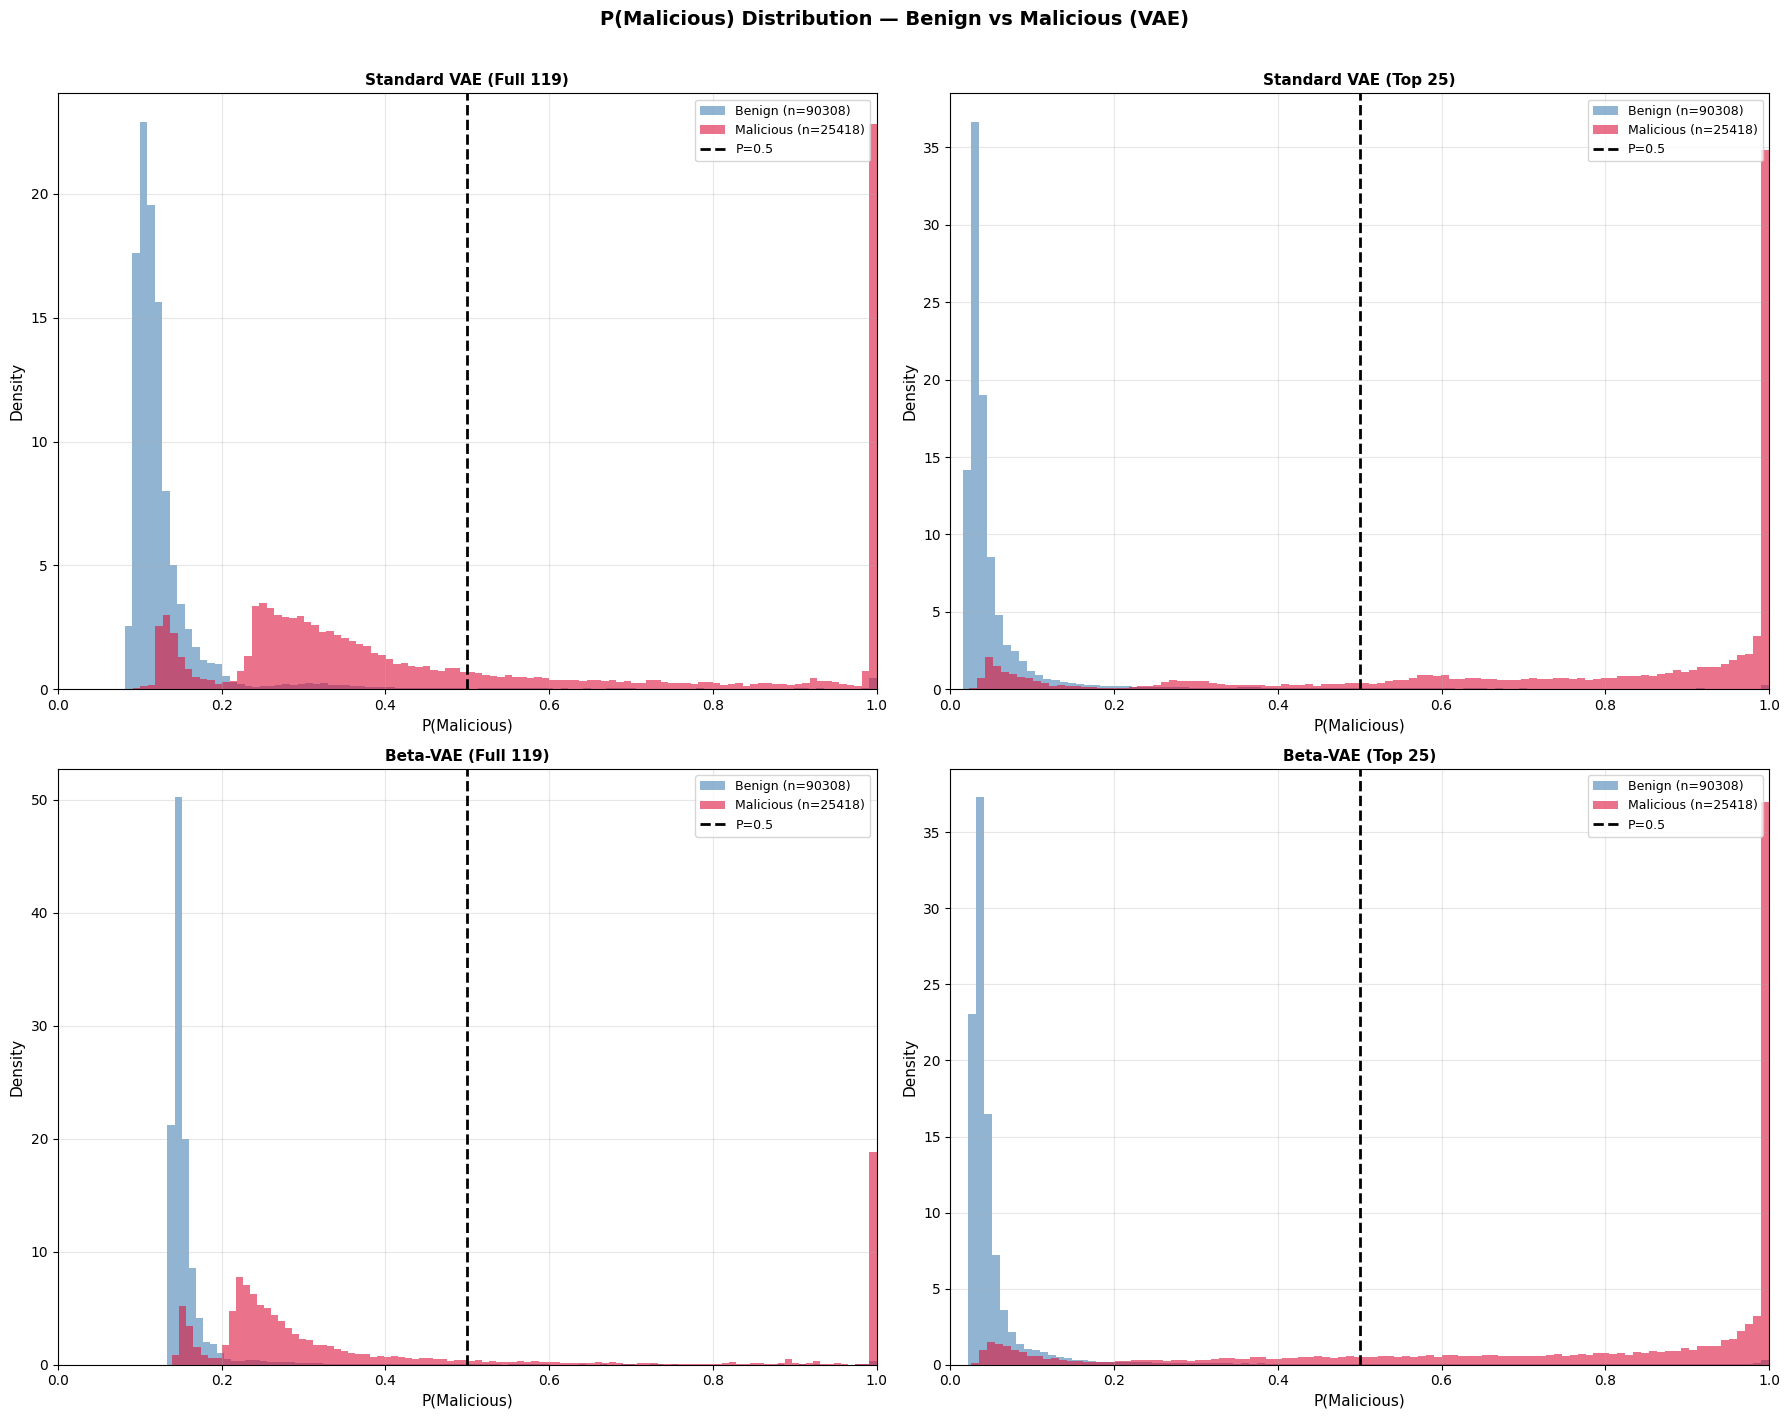

In [21]:
# ── Probability Distribution Plot ──
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

for idx, (name, probs) in enumerate(all_probs.items()):
    row, col = idx // 2, idx % 2
    ax = axes[row][col]

    benign_p = probs[y_malicious == 0]
    mal_p = probs[y_malicious == 1]

    ax.hist(benign_p, bins=100, alpha=0.6, color='steelblue', label=f'Benign (n={len(benign_p)})', density=True)
    ax.hist(mal_p, bins=100, alpha=0.6, color='crimson', label=f'Malicious (n={len(mal_p)})', density=True)
    ax.axvline(x=0.5, color='black', linestyle='--', linewidth=2, label='P=0.5')
    ax.set_xlabel('P(Malicious)', fontsize=11)
    ax.set_ylabel('Density', fontsize=11)
    ax.set_title(f'{name}', fontsize=11, fontweight='bold')
    ax.legend(fontsize=9)
    ax.set_xlim(0, 1)
    ax.grid(True, alpha=0.3)

plt.suptitle('P(Malicious) Distribution — Benign vs Malicious (VAE)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('vae_anomaly_detector_outputs/vae_probability_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

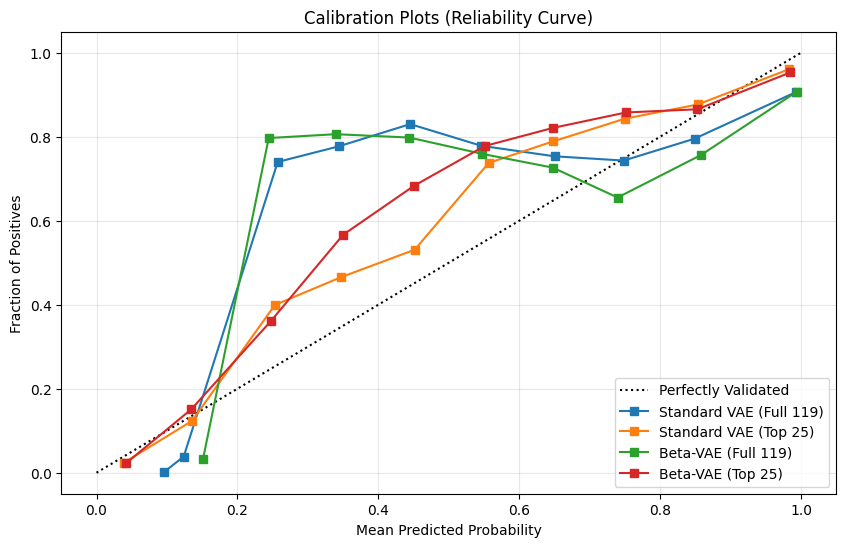

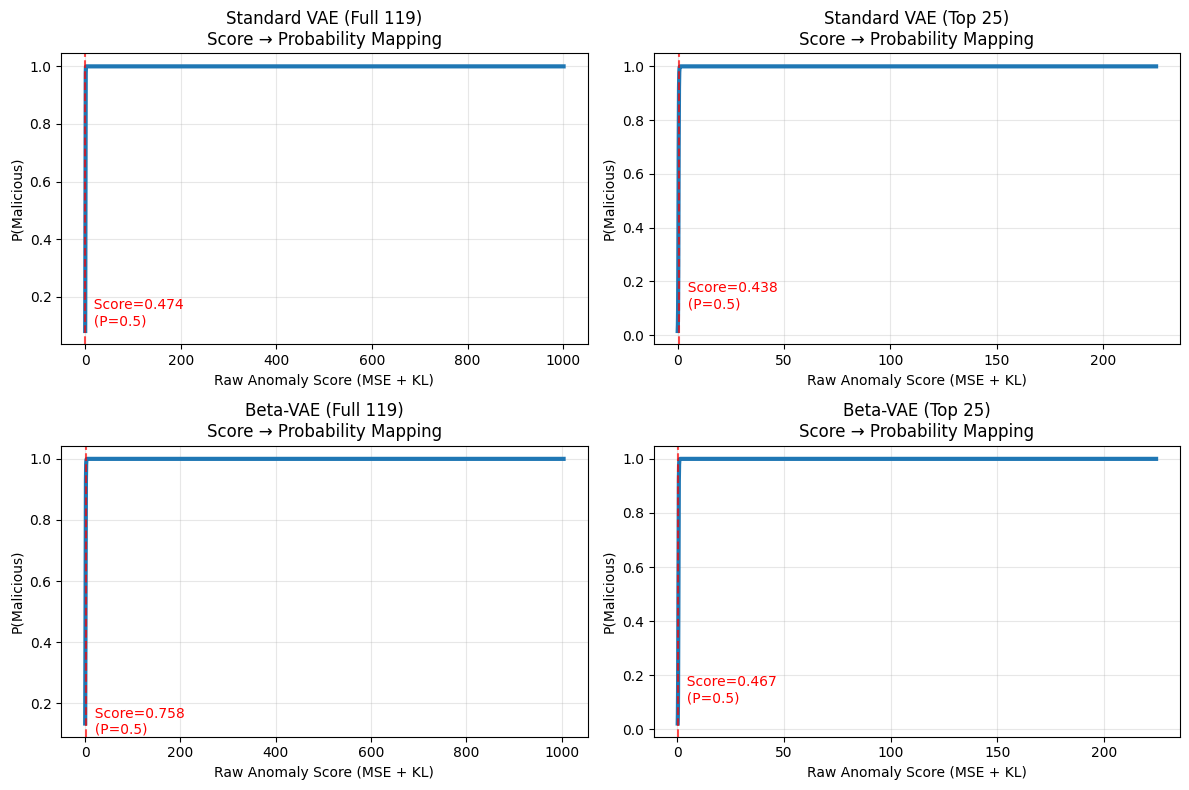


=== SAMPLE PREDICTIONS WITH PROBABILITIES (First 100 Test Samples) ===
----------------------------------------------------------------------------------------------------
Index    True Label   Raw Score    Probability  Prediction   Status
----------------------------------------------------------------------------------------------------
0        Benign       0.1576       0.0463       Benign       ✓
1126     Malicious    0.8145       0.9831       Malicious    ✓
1124     Malicious    109.8969     1.0000       Malicious    ✓
1        Benign       0.1520       0.0437       Benign       ✓
8        Benign       0.2815       0.1560       Benign       ✓
5        Benign       0.2580       0.1254       Benign       ✓
1042     Malicious    0.8175       0.9836       Malicious    ✓
3        Benign       0.3058       0.1936       Benign       ✓
1127     Malicious    0.7808       0.9758       Malicious    ✓
1125     Malicious    224.5520     1.0000       Malicious    ✓
1093     Malicious    197.42

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Ensure labels are available
if 'y_test' not in locals():
    y_test = y_malicious  # Use y_malicious from data loading step

# Construct calibrators dictionary (if not already defined)
if 'prob_calibrators' not in locals():
    prob_calibrators = {
        'Standard VAE (Full 119)': cal_vae_full,
        'Standard VAE (Top 25)': cal_vae_reduced,
        'Beta-VAE (Full 119)': cal_beta_full,
        'Beta-VAE (Top 25)': cal_beta_reduced,
    }

# --- 13. Calibration Curves ---
plt.figure(figsize=(10, 6))
plt.plot([0, 1], [0, 1], "k:", label="Perfectly Validated")

for name, probs in all_probs.items():
    fraction_of_positives, mean_predicted_value = calibration_curve(y_test, probs, n_bins=10)
    plt.plot(mean_predicted_value, fraction_of_positives, "s-", label=name)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Positives")
plt.ylim([-0.05, 1.05])
plt.legend(loc="lower right")
plt.title("Calibration Plots (Reliability Curve)")
plt.grid(True, alpha=0.3)
plt.show()

# --- 14. Anomaly Score to Probability Mapping ---
# Show how raw anomaly scores map to probabilities using the trained Logistic Regression
plt.figure(figsize=(12, 8))

# Define model names list consistent with all_probs keys
model_names_list = list(all_probs.keys())
# Define corresponding raw scores list using CORRECT variable names
scores_list = [
    scores_vae_full,
    scores_vae_reduced,
    scores_beta_full,
    scores_beta_reduced
]

for i, (name, scores) in enumerate(zip(model_names_list, scores_list)):
    # Sort by score for clean plotting
    sorted_indices = np.argsort(scores)
    sorted_scores = scores[sorted_indices]
    
    # Get corresponding probabilities
    calibrator = prob_calibrators[name]
    sorted_probs = calibrator.predict_proba(sorted_scores.reshape(-1, 1))[:, 1]
    
    plt.subplot(2, 2, i+1)
    plt.plot(sorted_scores, sorted_probs, lw=3)
    plt.title(f"{name}\nScore → Probability Mapping")
    plt.xlabel("Raw Anomaly Score (MSE + KL)")
    plt.ylabel("P(Malicious)")
    plt.grid(True, alpha=0.3)
    
    # Add vertical lines for decision thresholds (where P=0.5)
    # Find score where prob crosses 0.5
    idx_05 = np.searchsorted(sorted_probs, 0.5)
    if idx_05 < len(sorted_scores):
        thresh_score = sorted_scores[idx_05]
        plt.axvline(x=thresh_score, color='r', linestyle='--', alpha=0.7)
        plt.text(thresh_score, 0.1, f"  Score={thresh_score:.3f}\n  (P=0.5)", color='r')

plt.tight_layout()
plt.show()

# --- 15. Example Output Table with Probabilities ---
print("\n=== SAMPLE PREDICTIONS WITH PROBABILITIES (First 100 Test Samples) ===")
print("-" * 100)
print(f"{'Index':<8} {'True Label':<12} {'Raw Score':<12} {'Probability':<12} {'Prediction':<12} {'Status'}")
print("-" * 100)

# Use Standard VAE Top 25 for the example as it's often the best performer
example_model_name = "Standard VAE (Top 25)"
ex_scores = scores_vae_reduced # Correct variable
ex_probs = all_probs[example_model_name]
ex_threshold = 0.5 # Prob threshold

# Get mixed samples (some benign, some malicious)
indices = np.concatenate([
    np.where(y_test == 0)[0][:10],
    np.where(y_test == 1)[0][:10]
])
np.random.shuffle(indices)

for idx in indices:
    true_cls = "Malicious" if y_test[idx] == 1 else "Benign"
    pred_cls = "Malicious" if ex_probs[idx] > ex_threshold else "Benign"
    status = "✓" if true_cls == pred_cls else "✗"
    
    print(f"{idx:<8} {true_cls:<12} {ex_scores[idx]:<12.4f} {ex_probs[idx]:<12.4f} {pred_cls:<12} {status}")
print("-" * 100)

TRAINING HISTORY PLOTS


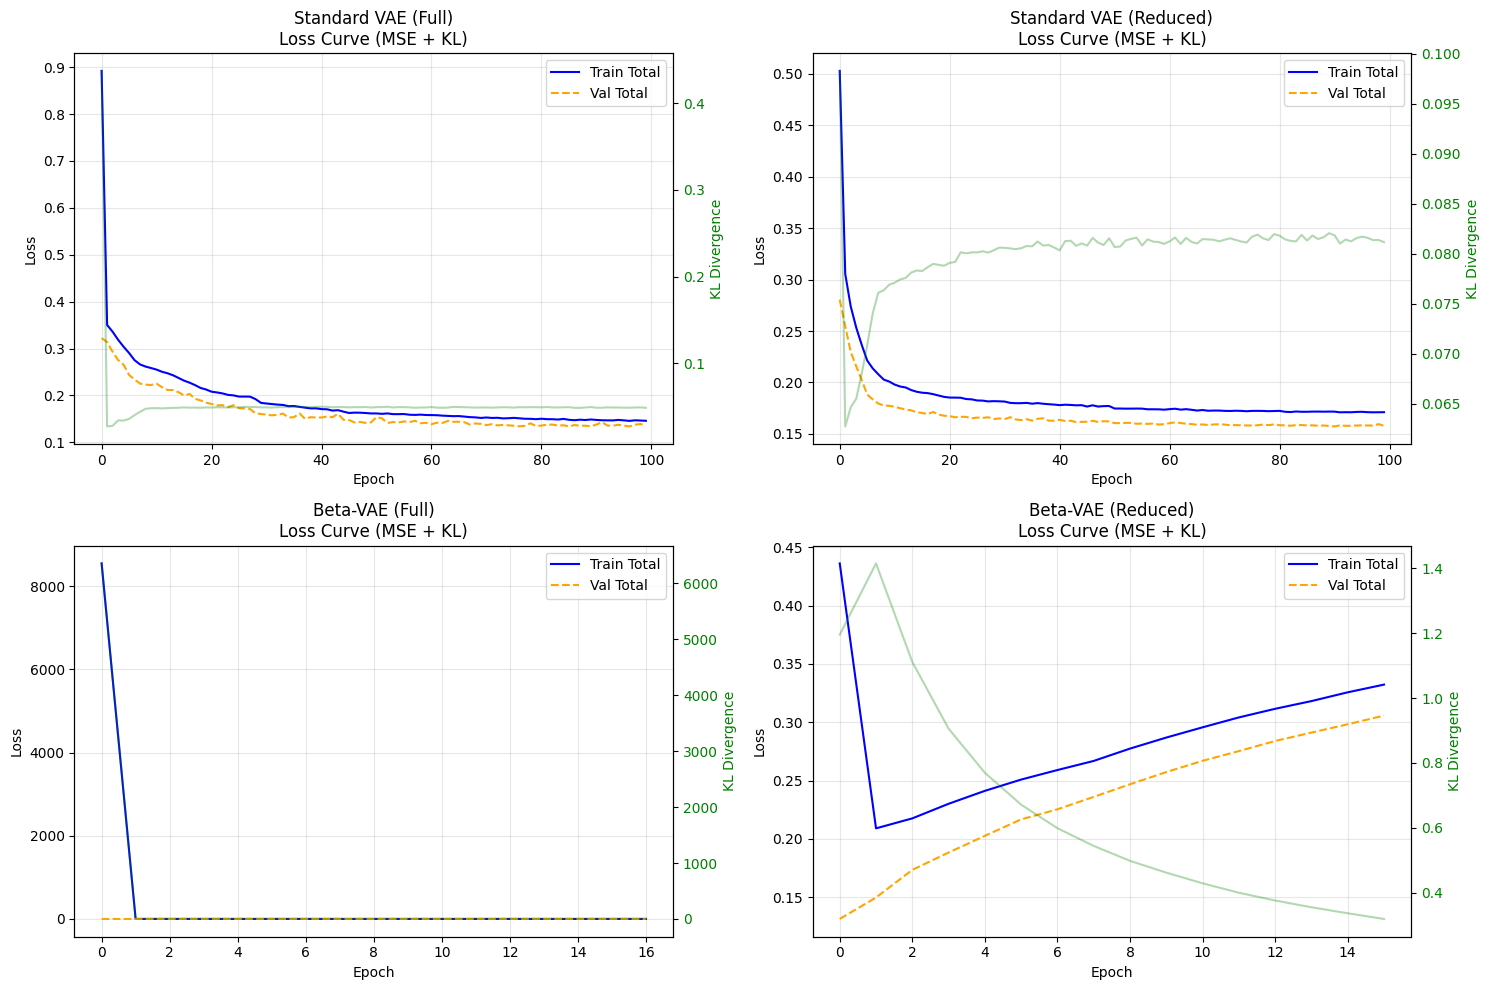


SAMPLE OUTPUT: Per-Event Malicious Probability (Best Model)
Model: Standard VAE (Top 25)
---------------------------------------------------------------------------
Index    True Label   Raw Score    Probability  Status
---------------------------------------------------------------------------
62622    Benign       0.0837       0.0214       Correct
6117     Benign       0.1025       0.0261       Correct
25450    Benign       0.1795       0.0579       Correct
6976     Benign       0.1116       0.0287       Correct
35115    Benign       0.1433       0.0400       Correct
13664    Benign       0.1068       0.0273       Correct
46438    Benign       0.1065       0.0272       Correct
63392    Benign       0.4134       0.4339       Correct
31729    Benign       0.1654       0.0502       Correct
112066   Benign       0.1400       0.0386       Correct
64245    Benign       0.1123       0.0289       Correct
20292    Benign       0.1050       0.0268       Correct
68318    Benign       0.0787   

In [26]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Ensure helper variables are available
if 'all_scores' not in locals():
    all_scores = [
        scores_vae_full,
        scores_vae_reduced,
        scores_beta_full,
        scores_beta_reduced
    ]
    labels_names = list(all_probs.keys())

# --- 11. Plot Training History ---
print("="*70)
print("TRAINING HISTORY PLOTS")
print("="*70)

# Create output df for easier plotting
# We have `history_vae_full`, `history_vae_reduced`, `history_beta_full`, `history_beta_reduced`
histories = [
    ('Standard VAE (Full)', history_vae_full),
    ('Standard VAE (Reduced)', history_vae_reduced),
    ('Beta-VAE (Full)', history_beta_full),
    ('Beta-VAE (Reduced)', history_beta_reduced)
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for i, (name, hist) in enumerate(histories):
    ax = axes[i]
    ax.plot(hist['train_total'], label='Train Total', color='blue')
    ax.plot(hist['val_total'], label='Val Total', color='orange', linestyle='--')
    ax.set_title(f"{name}\nLoss Curve (MSE + KL)")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # Add secondary axis for KL loss if available
    ax2 = ax.twinx()
    ax2.plot(hist['train_kl'], label='Train KL', color='green', alpha=0.3)
    ax2.set_ylabel("KL Divergence", color='green')
    ax2.tick_params(axis='y', labelcolor='green')

plt.tight_layout()
plt.savefig('vae_anomaly_detector_outputs/vae_feature_selection_training_curves.png')
plt.show()

# --- Print example predictions ---
print("\n" + "="*90)
print("SAMPLE OUTPUT: Per-Event Malicious Probability (Best Model)")
print("="*90)

# Identify best model by ROC-AUC (already computed in results_df if available, or just use Reduced Standard VAE)
try:
    # If results_df exists
    best_idx = results_df['ROC-AUC'].argmax()
    best_model_name = results_df.index[best_idx]
except:
    best_model_name = 'Standard VAE (Top 25)'

best_probs = all_probs[best_model_name]
# Get corresponding scores array
idx_map = {name: i for i, name in enumerate(labels_names)}
best_scores_arr = all_scores[idx_map[best_model_name]]

# Create a sample dataframe
sample_indices = np.random.choice(len(y_test), 15, replace=False)
sample_df = pd.DataFrame({
    'Index': sample_indices,
    'True_Label': ['Malicious' if y == 1 else 'Benign' for y in y_test[sample_indices]],
    'Anomaly_Score': best_scores_arr[sample_indices],
    'Cablib_Prob': best_probs[sample_indices]
})

print(f"Model: {best_model_name}")
print("-" * 75)
print(f"{'Index':<8} {'True Label':<12} {'Raw Score':<12} {'Probability':<12} {'Status'}")
print("-" * 75)
for _, row in sample_df.iterrows():
    status = "Correct" if (row['True_Label']=='Malicious' and row['Cablib_Prob']>0.5) or \
                          (row['True_Label']=='Benign' and row['Cablib_Prob']<=0.5) else "Miss"
    print(f"{int(row['Index']):<8} {row['True_Label']:<12} {row['Anomaly_Score']:<12.4f} {row['Cablib_Prob']:<12.4f} {status}")
print("-" * 75)

## Part 11: Training Loss Curves Comparison

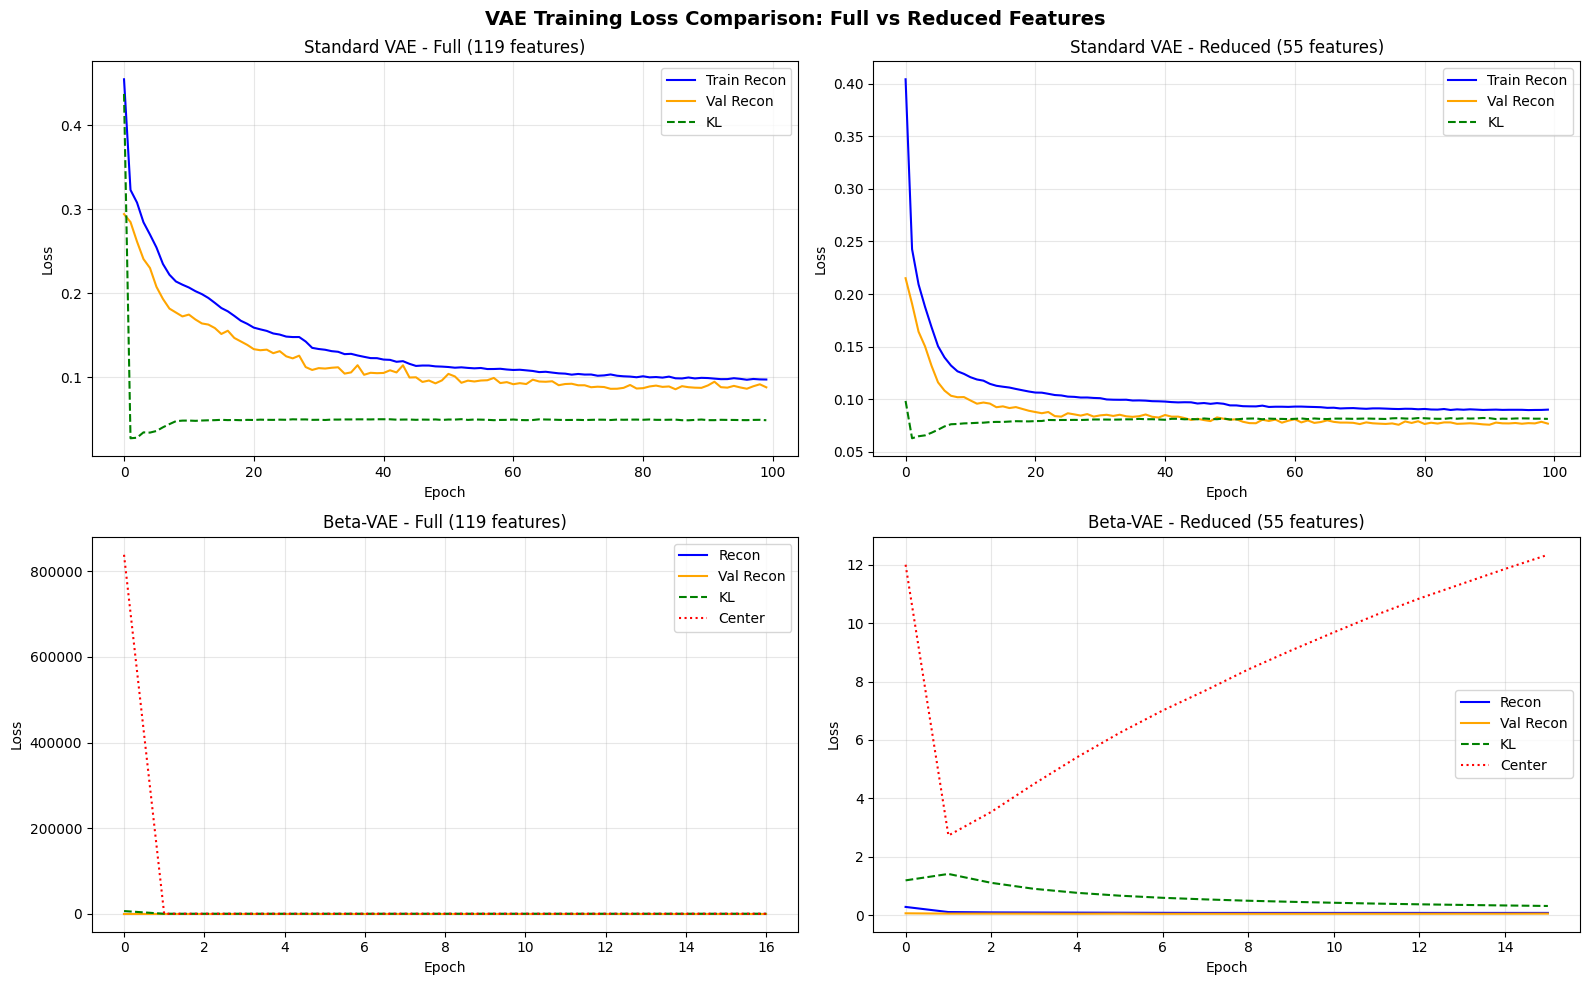

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('VAE Training Loss Comparison: Full vs Reduced Features', fontsize=14, fontweight='bold')

# Standard VAE - Full
axes[0,0].plot(history_vae_full['train_recon'], label='Train Recon', color='blue')
axes[0,0].plot(history_vae_full['val_recon'], label='Val Recon', color='orange')
axes[0,0].plot(history_vae_full['train_kl'], label='KL', color='green', linestyle='--')
axes[0,0].set_title(f'Standard VAE - Full ({input_dim_full} features)')
axes[0,0].set_xlabel('Epoch'); axes[0,0].set_ylabel('Loss')
axes[0,0].legend(); axes[0,0].grid(True, alpha=0.3)

# Standard VAE - Reduced
axes[0,1].plot(history_vae_reduced['train_recon'], label='Train Recon', color='blue')
axes[0,1].plot(history_vae_reduced['val_recon'], label='Val Recon', color='orange')
axes[0,1].plot(history_vae_reduced['train_kl'], label='KL', color='green', linestyle='--')
axes[0,1].set_title(f'Standard VAE - Reduced ({input_dim_reduced} features)')
axes[0,1].set_xlabel('Epoch'); axes[0,1].set_ylabel('Loss')
axes[0,1].legend(); axes[0,1].grid(True, alpha=0.3)

# Beta-VAE - Full
axes[1,0].plot(history_beta_full['train_recon'], label='Recon', color='blue')
axes[1,0].plot(history_beta_full['val_recon'], label='Val Recon', color='orange')
axes[1,0].plot(history_beta_full['train_kl'], label='KL', color='green', linestyle='--')
axes[1,0].plot(history_beta_full['train_center'], label='Center', color='red', linestyle=':')
axes[1,0].set_title(f'Beta-VAE - Full ({input_dim_full} features)')
axes[1,0].set_xlabel('Epoch'); axes[1,0].set_ylabel('Loss')
axes[1,0].legend(); axes[1,0].grid(True, alpha=0.3)

# Beta-VAE - Reduced
axes[1,1].plot(history_beta_reduced['train_recon'], label='Recon', color='blue')
axes[1,1].plot(history_beta_reduced['val_recon'], label='Val Recon', color='orange')
axes[1,1].plot(history_beta_reduced['train_kl'], label='KL', color='green', linestyle='--')
axes[1,1].plot(history_beta_reduced['train_center'], label='Center', color='red', linestyle=':')
axes[1,1].set_title(f'Beta-VAE - Reduced ({input_dim_reduced} features)')
axes[1,1].set_xlabel('Epoch'); axes[1,1].set_ylabel('Loss')
axes[1,1].legend(); axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('vae_anomaly_detector_outputs/vae_feature_selection_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## Part 12: ROC & Precision-Recall Curve Comparison

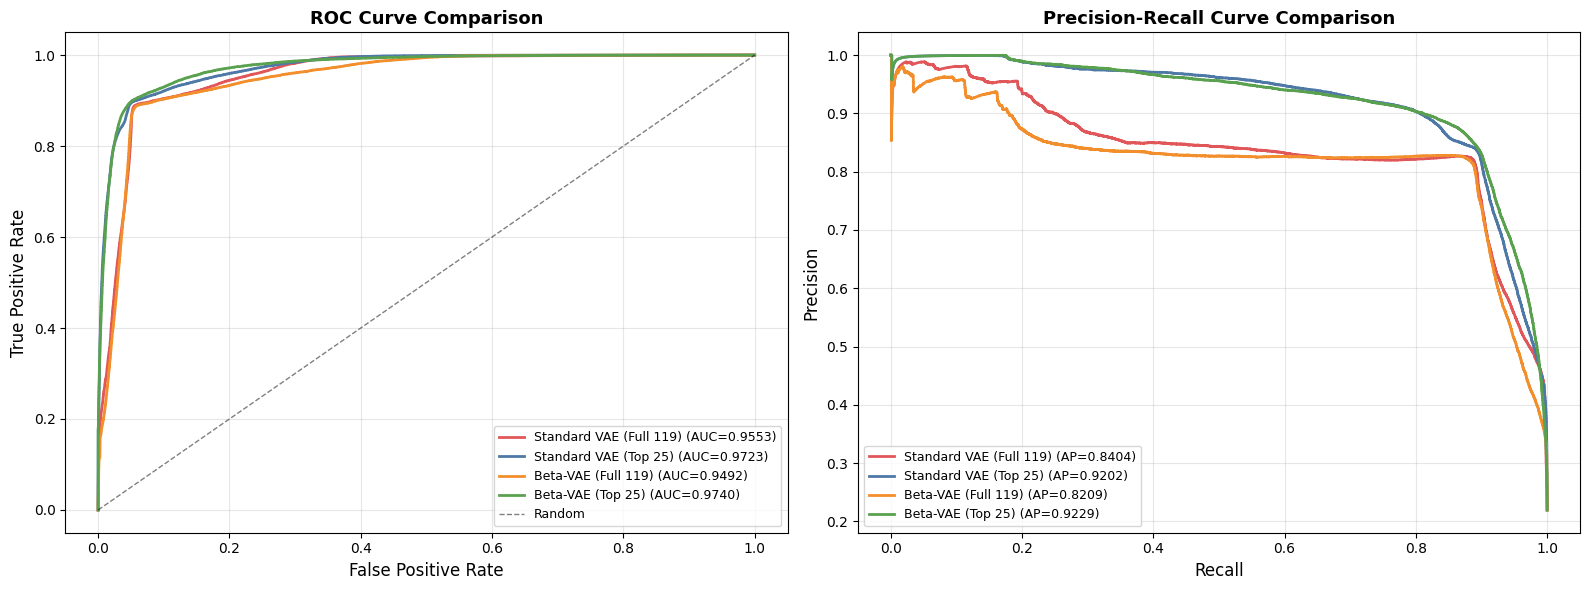

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

colors = ['#e15759', '#4e79a7', '#f28e2b', '#59a14f']
labels_names = list(all_results.keys())
all_scores = [scores_vae_full, scores_vae_reduced, scores_beta_full, scores_beta_reduced]

# ROC Curves
for i, (name, scores) in enumerate(zip(labels_names, all_scores)):
    fpr, tpr, _ = roc_curve(y_malicious, scores)
    auc_val = roc_auc_score(y_malicious, scores)
    axes[0].plot(fpr, tpr, color=colors[i], lw=2, label=f'{name} (AUC={auc_val:.4f})')

axes[0].plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5, label='Random')
axes[0].set_xlabel('False Positive Rate', fontsize=12)
axes[0].set_ylabel('True Positive Rate', fontsize=12)
axes[0].set_title('ROC Curve Comparison', fontsize=13, fontweight='bold')
axes[0].legend(loc='lower right', fontsize=9)
axes[0].grid(True, alpha=0.3)

# Precision-Recall Curves
for i, (name, scores) in enumerate(zip(labels_names, all_scores)):
    prec, rec, _ = precision_recall_curve(y_malicious, scores)
    ap = average_precision_score(y_malicious, scores)
    axes[1].plot(rec, prec, color=colors[i], lw=2, label=f'{name} (AP={ap:.4f})')

axes[1].set_xlabel('Recall', fontsize=12)
axes[1].set_ylabel('Precision', fontsize=12)
axes[1].set_title('Precision-Recall Curve Comparison', fontsize=13, fontweight='bold')
axes[1].legend(loc='lower left', fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('vae_anomaly_detector_outputs/vae_feature_selection_roc_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## Part 13: Confusion Matrix Comparison

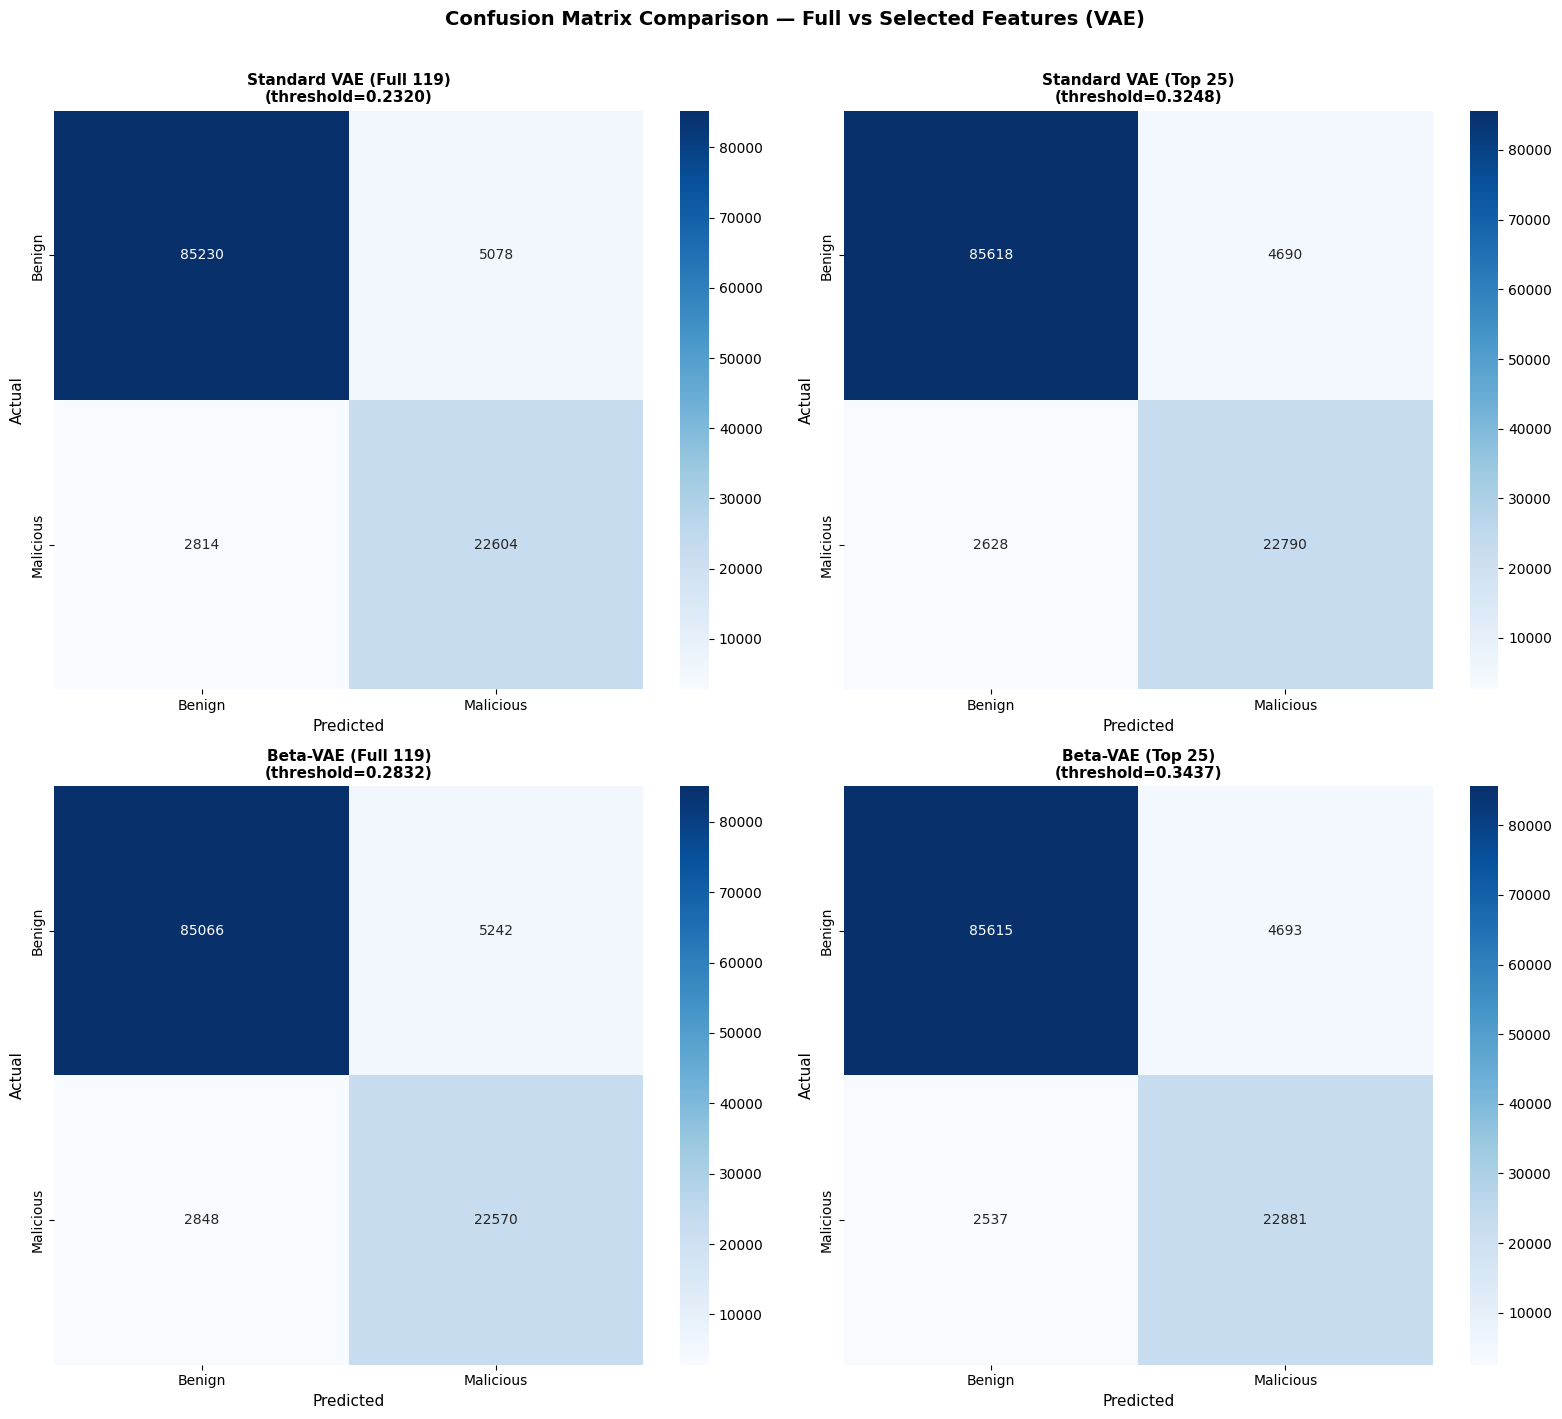

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

all_thresholds = [th_vae_full, th_vae_reduced, th_beta_full, th_beta_reduced]

for idx, (name, scores, th) in enumerate(zip(labels_names, all_scores, all_thresholds)):
    preds = (scores > th).astype(int)
    cm = confusion_matrix(y_malicious, preds)
    row, col = idx // 2, idx % 2

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[row][col],
                xticklabels=['Benign', 'Malicious'], yticklabels=['Benign', 'Malicious'])
    axes[row][col].set_xlabel('Predicted', fontsize=11)
    axes[row][col].set_ylabel('Actual', fontsize=11)
    axes[row][col].set_title(f'{name}\n(threshold={th:.4f})', fontsize=11, fontweight='bold')

plt.suptitle('Confusion Matrix Comparison \u2014 Full vs Selected Features (VAE)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('vae_anomaly_detector_outputs/vae_feature_selection_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

## Part 14: Reconstruction Error Distribution

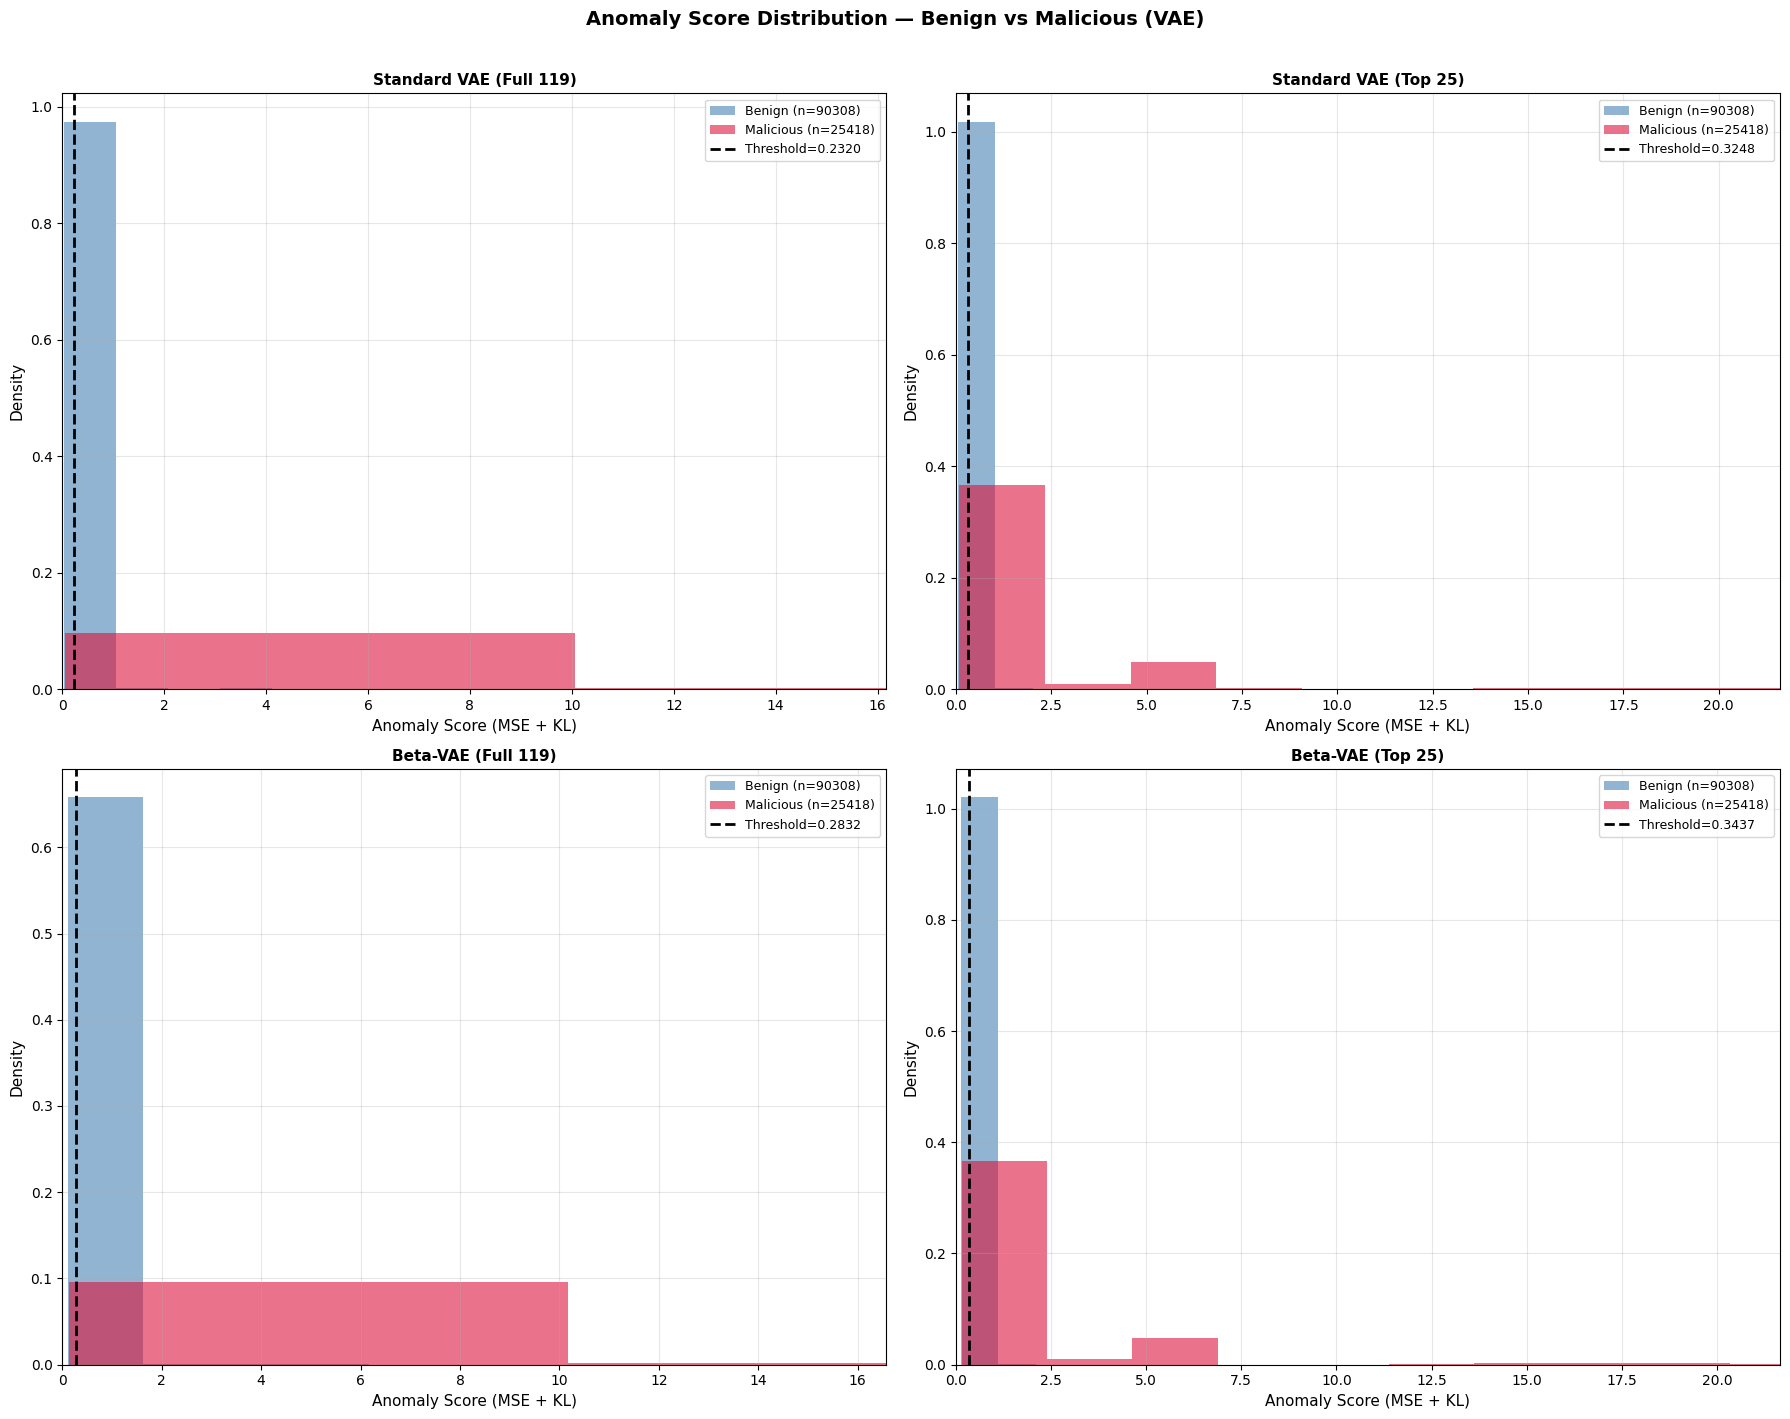

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

for idx, (name, scores) in enumerate(zip(labels_names, all_scores)):
    row, col = idx // 2, idx % 2
    ax = axes[row][col]

    benign_scores = scores[y_malicious == 0]
    malicious_scores = scores[y_malicious == 1]

    ax.hist(benign_scores, bins=100, alpha=0.6, color='steelblue', label=f'Benign (n={len(benign_scores)})', density=True)
    ax.hist(malicious_scores, bins=100, alpha=0.6, color='crimson', label=f'Malicious (n={len(malicious_scores)})', density=True)

    ax.axvline(x=all_thresholds[idx], color='black', linestyle='--', linewidth=2, label=f'Threshold={all_thresholds[idx]:.4f}')
    ax.set_xlabel('Anomaly Score (MSE + KL)', fontsize=11)
    ax.set_ylabel('Density', fontsize=11)
    ax.set_title(f'{name}', fontsize=11, fontweight='bold')
    ax.legend(fontsize=9)
    ax.set_xlim(0, np.percentile(scores, 99.5))
    ax.grid(True, alpha=0.3)

plt.suptitle('Anomaly Score Distribution \u2014 Benign vs Malicious (VAE)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('vae_anomaly_detector_outputs/vae_feature_selection_error_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## Part 15: t-SNE Latent Space Visualization

Latent vectors shape — Full: (5000, 32), Reduced: (5000, 32)


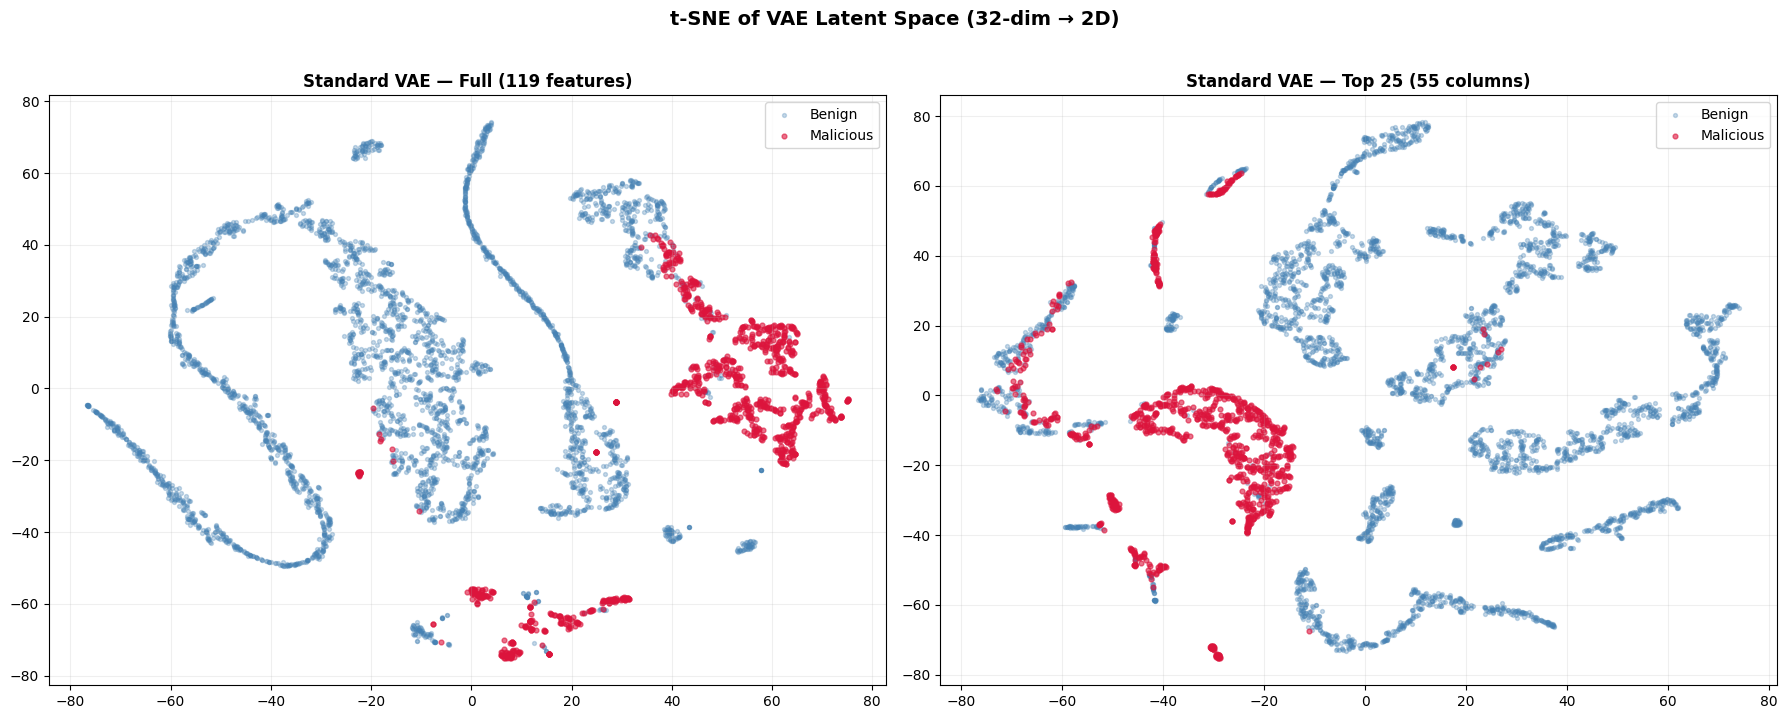

In [31]:
from sklearn.manifold import TSNE

# Use a subsample for t-SNE (too slow on full dataset)
np.random.seed(42)
n_subsample = 5000
sub_idx = np.random.choice(len(X_full_scaled), n_subsample, replace=False)

y_sub = y_malicious[sub_idx]

# Get latent vectors from standard VAE models
latent_full = get_latent_vectors_vae(model_vae_full, X_full_scaled[sub_idx], is_beta=False, device=device)
latent_reduced = get_latent_vectors_vae(model_vae_reduced, X_reduced_scaled[sub_idx], is_beta=False, device=device)

print(f"Latent vectors shape \u2014 Full: {latent_full.shape}, Reduced: {latent_reduced.shape}")

# t-SNE
tsne_full = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
tsne_reduced = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)

emb_full = tsne_full.fit_transform(latent_full)
emb_reduced = tsne_reduced.fit_transform(latent_reduced)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, emb, title in zip(axes, [emb_full, emb_reduced],
                           ['Standard VAE \u2014 Full (119 features)', 'Standard VAE \u2014 Top 25 (55 columns)']):
    benign_mask_sub = y_sub == 0
    malicious_mask_sub = y_sub == 1
    ax.scatter(emb[benign_mask_sub, 0], emb[benign_mask_sub, 1], c='steelblue', alpha=0.3, s=8, label='Benign')
    ax.scatter(emb[malicious_mask_sub, 0], emb[malicious_mask_sub, 1], c='crimson', alpha=0.6, s=12, label='Malicious')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.2)

plt.suptitle('t-SNE of VAE Latent Space (32-dim \u2192 2D)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('vae_anomaly_detector_outputs/vae_feature_selection_tsne_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Part 16: Save Models & Results

In [32]:
import json
import pickle

output_dir = 'vae_anomaly_detector_outputs'
os.makedirs(output_dir, exist_ok=True)

# Save models
torch.save(model_vae_full.state_dict(), f'{output_dir}/vae_full_features.pth')
torch.save(model_vae_reduced.state_dict(), f'{output_dir}/vae_top25_features.pth')
torch.save(model_beta_full.state_dict(), f'{output_dir}/beta_vae_full_features.pth')
torch.save(model_beta_reduced.state_dict(), f'{output_dir}/beta_vae_top25_features.pth')

# Save comparison results
comparison_df = pd.DataFrame(all_results).T
comparison_df.to_csv(f'{output_dir}/vae_feature_selection_comparison.csv')

# Save selected features list
feature_info = {
    'n_conceptual_features': 25,
    'n_actual_columns': len(selected_columns),
    'log_secbert_dims': len(log_secbert_cols),
    'cmd_secbert_dims': len(cmd_secbert_cols),
    'n_individual_features': len(top_individual_features),
    'individual_features': top_individual_features,
    'all_selected_columns': selected_columns
}
with open(f'{output_dir}/selected_features_top25.json', 'w') as f:
    json.dump(feature_info, f, indent=2)

# Save latent vectors
latent_full_all = get_latent_vectors_vae(model_vae_full, X_full_scaled, is_beta=False, device=device)
latent_reduced_all = get_latent_vectors_vae(model_vae_reduced, X_reduced_scaled, is_beta=False, device=device)
np.save(f'{output_dir}/latent_vae_full_features.npy', latent_full_all)
np.save(f'{output_dir}/latent_vae_top25_features.npy', latent_reduced_all)

# Save malicious probabilities for all models
probs_df = pd.DataFrame({
    'true_label': y_malicious,
    'score_vae_full': scores_vae_full,
    'score_vae_reduced': scores_vae_reduced,
    'score_beta_full': scores_beta_full,
    'score_beta_reduced': scores_beta_reduced,
    'prob_vae_full': probs_vae_full,
    'prob_vae_reduced': probs_vae_reduced,
    'prob_beta_full': probs_beta_full,
    'prob_beta_reduced': probs_beta_reduced,
})
probs_df.to_csv(f'{output_dir}/malicious_probabilities.csv', index=False)

# Save probability calibrators (logistic regression models)
calibrators = {
    'Standard VAE (Full 119)': cal_vae_full,
    'Standard VAE (Top 25)': cal_vae_reduced,
    'Beta-VAE (Full 119)': cal_beta_full,
    'Beta-VAE (Top 25)': cal_beta_reduced,
}
with open(f'{output_dir}/probability_calibrators.pkl', 'wb') as f:
    pickle.dump(calibrators, f)

print("All VAE models, probabilities, and results saved!")
print(f"\nFiles saved to '{output_dir}/':\n")
for f_name in ['vae_full_features.pth', 'vae_top25_features.pth',
               'beta_vae_full_features.pth', 'beta_vae_top25_features.pth',
               'vae_feature_selection_comparison.csv',
               'selected_features_top25.json',
               'latent_vae_full_features.npy', 'latent_vae_top25_features.npy',
               'malicious_probabilities.csv', 'probability_calibrators.pkl']:
    print(f"  \u2713 {f_name}")

All VAE models, probabilities, and results saved!

Files saved to 'vae_anomaly_detector_outputs/':

  ✓ vae_full_features.pth
  ✓ vae_top25_features.pth
  ✓ beta_vae_full_features.pth
  ✓ beta_vae_top25_features.pth
  ✓ vae_feature_selection_comparison.csv
  ✓ selected_features_top25.json
  ✓ latent_vae_full_features.npy
  ✓ latent_vae_top25_features.npy
  ✓ malicious_probabilities.csv
  ✓ probability_calibrators.pkl


## Part 17: Final Summary & Recommendation

### Experiment Recap
- **Objective:** Determine if reducing from **119 features** to the **top 25 conceptual features** (55 actual columns) improves VAE-based APT anomaly detection
- **Method:** Trained 4 models (Standard VAE + Beta-VAE × Full vs Reduced features), benign-only training
- **Top 25 features** selected via ensemble importance (RF, XGB, LightGBM, Permutation, Mutual Information, F-Score)
- **Feature groups:** 16 log_secbert_emb dims + 16 cmd_secbert_emb dims + 23 individual features

### Key Metrics Compared
| Metric | What it measures |
|--------|------------------|
| ROC-AUC | Overall ranking quality |
| F1-Score | Balance of precision and recall |
| Balanced Accuracy | Accounts for class imbalance |
| Average Precision | Area under PR curve |

In [33]:
# Final comparison summary
print("=" * 80)
print("FINAL COMPARISON: Feature Selection Impact on VAE Anomaly Detection")
print("=" * 80)

comp_df = pd.DataFrame(all_results).T
print(f"\n{'Model':<35} {'ROC-AUC':>10} {'F1':>10} {'Bal.Acc':>10} {'Precision':>10} {'Recall':>10}")
print("-" * 85)
for name, row in comp_df.iterrows():
    print(f"{name:<35} {row['ROC-AUC']:>10.4f} {row['F1']:>10.4f} {row['Balanced Acc']:>10.4f} {row['Precision']:>10.4f} {row['Recall']:>10.4f}")

print("\n" + "=" * 80)
print("DELTAS (Reduced - Full):")
print("=" * 80)

# Standard VAE delta
vae_full_row = comp_df.loc['Standard VAE (Full 119)']
vae_red_row = comp_df.loc['Standard VAE (Top 25)']
print(f"\n{'Standard VAE:':<25}")
for metric in ['ROC-AUC', 'F1', 'Balanced Acc', 'Precision', 'Recall']:
    delta = vae_red_row[metric] - vae_full_row[metric]
    sign = '+' if delta >= 0 else ''
    symbol = '\u2713 IMPROVED' if delta > 0 else ('= SAME' if delta == 0 else '\u2717 DECREASED')
    print(f"  {metric:<20} {sign}{delta:.4f}  {symbol}")

# Beta-VAE delta
beta_full_row = comp_df.loc['Beta-VAE (Full 119)']
beta_red_row = comp_df.loc['Beta-VAE (Top 25)']
print(f"\n{'Beta-VAE:':<25}")
for metric in ['ROC-AUC', 'F1', 'Balanced Acc', 'Precision', 'Recall']:
    delta = beta_red_row[metric] - beta_full_row[metric]
    sign = '+' if delta >= 0 else ''
    symbol = '\u2713 IMPROVED' if delta > 0 else ('= SAME' if delta == 0 else '\u2717 DECREASED')
    print(f"  {metric:<20} {sign}{delta:.4f}  {symbol}")

# Overall best model
print("\n" + "=" * 80)
best_model = comp_df['ROC-AUC'].idxmax()
best_auc = comp_df['ROC-AUC'].max()
print(f"BEST MODEL: {best_model}")
print(f"Best ROC-AUC: {best_auc:.4f}")
print(f"\nFeature reduction: 119 \u2192 55 columns ({(1 - 55/119)*100:.1f}% reduction)")
print(f"Conceptual features: 119 individual \u2192 25 grouped features")
print("=" * 80)

FINAL COMPARISON: Feature Selection Impact on VAE Anomaly Detection

Model                                  ROC-AUC         F1    Bal.Acc  Precision     Recall
-------------------------------------------------------------------------------------
Standard VAE (Full 119)                 0.9553     0.8514     0.9165     0.8166     0.8893
Standard VAE (Top 25)                   0.9723     0.8617     0.9223     0.8293     0.8966
Beta-VAE (Full 119)                     0.9492     0.8480     0.9150     0.8115     0.8880
Beta-VAE (Top 25)                       0.9740     0.8636     0.9241     0.8298     0.9002

DELTAS (Reduced - Full):

Standard VAE:            
  ROC-AUC              +0.0171  ✓ IMPROVED
  F1                   +0.0103  ✓ IMPROVED
  Balanced Acc         +0.0058  ✓ IMPROVED
  Precision            +0.0128  ✓ IMPROVED
  Recall               +0.0073  ✓ IMPROVED

Beta-VAE:                
  ROC-AUC              +0.0249  ✓ IMPROVED
  F1                   +0.0155  ✓ IMPROVED
  Balance

In [34]:
# Verify NO data leakage columns are present
leakage_keywords = ['rule_level', 'rule.level', 'rule_id', 'rule.id',
                     'mitre', 'MITRE', 'ckc', 'cyber_kill_chain',
                     'rule.mitre', 'rule_mitre']

all_cols = list(X_full_df.columns)
print("=" * 70)
print("DATA LEAKAGE VERIFICATION")
print("=" * 70)
print(f"\nFile used: feature_selection_outputs2/feature_matrix_no_leakage.parquet")
print(f"Total columns: {len(all_cols)}")

found_leakage = []
for col in all_cols:
    for kw in leakage_keywords:
        if kw.lower() in col.lower():
            found_leakage.append(col)
            break

if found_leakage:
    print(f"\n\u26a0\ufe0f WARNING: Found {len(found_leakage)} potential leakage columns:")
    for c in found_leakage:
        print(f"  - {c}")
else:
    print("\n\u2705 NO leakage columns found! Confirmed safe.")
    print("   \u2713 No rule.level / rule_level")
    print("   \u2713 No rule.id / rule_id")
    print("   \u2713 No MITRE ATT&CK columns")
    print("   \u2713 No CKC / cyber_kill_chain columns")

print(f"\nLabels (separate file, NOT features): {list(labels_df.columns)}")
print("   \u2192 malicious, ckc used only as Y targets, never as input features")

DATA LEAKAGE VERIFICATION

File used: feature_selection_outputs2/feature_matrix_no_leakage.parquet
Total columns: 119

✅ NO leakage columns found! Confirmed safe.
   ✓ No rule.level / rule_level
   ✓ No rule.id / rule_id
   ✓ No MITRE ATT&CK columns
   ✓ No CKC / cyber_kill_chain columns

Labels (separate file, NOT features): ['malicious', 'cyber_kill_chain_tactic', 'ckc_encoded']
   → malicious, ckc used only as Y targets, never as input features
